In [1]:
# Cell 1 — Environment check

import os
import sys
import platform

print("Python version:")
print(sys.version)

print("\nPlatform:")
print(platform.platform())

print("\nCPU cores:")
print(os.cpu_count())

print("\nOperating system:")
!cat /etc/os-release | grep PRETTY_NAME

print("\nGPU information:")
!nvidia-smi

Python version:
3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]

Platform:
Linux-6.6.122+-x86_64-with-glibc2.35

CPU cores:
8

Operating system:
PRETTY_NAME="Ubuntu 22.04.5 LTS"

GPU information:
Thu Oct  8 15:10:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             12W

In [2]:
# Cell 2 — Install and import required libraries

!pip install -q tensorflow_decision_forests==1.12.0
!pip install -q imbalanced-learn

import os
import time
import gc
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import tensorflow_decision_forests as tfdf

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print(
    "TensorFlow Decision Forests version:",
    tfdf.__version__
)

TensorFlow version: 2.19.0
TensorFlow Decision Forests version: 1.12.0


In [3]:
# Cell 3 — Mount Google Drive

from google.colab import drive

drive.mount(
    "/content/drive"
)

print(
    "Google Drive mounted."
)

Mounted at /content/drive
Google Drive mounted.


In [4]:
# Cell 4 — Define project paths

PROJECT_DIR = (
    "/content/drive/MyDrive/MSc_Project"
)

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "CICIDS2017",
    "processed"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_F1_CIC"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "RF_F1_CIC"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

TRAIN_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_train.parquet"
)

VAL_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_validation.parquet"
)

TEST_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_test.parquet"
)

BEST_TUNING_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H3_CIC",
    "RF_best_tuned_configuration.csv"
)

RF_H2_METRICS_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H2_CIC",
    "RF_H2_CIC_metrics.csv"
)

LABEL_COL = "Label"

print(
    "RF-F1 results directory:"
)

print(
    RESULTS_DIR
)

print(
    "\nRF-F1 model directory:"
)

print(
    MODEL_DIR
)

RF-F1 results directory:
/content/drive/MyDrive/MSc_Project/results/RF_F1_CIC

RF-F1 model directory:
/content/drive/MyDrive/MSc_Project/models/RF_F1_CIC


In [5]:
# Cell 5 — Verify frozen datasets
# and selected tuning configuration

required_files = {
    "CIC training set":
        TRAIN_PATH,

    "CIC validation set":
        VAL_PATH,

    "CIC test set":
        TEST_PATH,

    "Best tuned configuration":
        BEST_TUNING_PATH,

    "RF-H2 final metrics":
        RF_H2_METRICS_PATH
}

print(
    "Frozen input file checks:\n"
)

all_files_exist = True

for name, path in required_files.items():

    exists = os.path.exists(
        path
    )

    print(
        f"{name}: {exists}"
    )

    if not exists:

        print(
            "  Missing:",
            path
        )

        all_files_exist = False

if not all_files_exist:

    raise FileNotFoundError(
        "One or more frozen inputs are missing."
    )

# --------------------------------------------------
# Load selected tuning configuration
# --------------------------------------------------

best_tuning_df = pd.read_csv(
    BEST_TUNING_PATH
)

print(
    "\nFrozen best tuned configuration:"
)

display(
    best_tuning_df
)

BEST_TUNED_MODEL = str(
    best_tuning_df.iloc[0][
        "Selected Model"
    ]
)

BEST_TUNED_TREES = int(
    best_tuning_df.iloc[0][
        "Trees"
    ]
)

BEST_TUNED_MAX_DEPTH = int(
    best_tuning_df.iloc[0][
        "Max Depth"
    ]
)

BEST_TUNED_MIN_EXAMPLES = int(
    best_tuning_df.iloc[0][
        "Min Examples"
    ]
)

BEST_TUNED_RANDOM_SEED = int(
    best_tuning_df.iloc[0][
        "Random Seed"
    ]
)

print(
    "\nConfiguration carried into "
    "feature refinement:"
)

print(
    "Selected model:",
    BEST_TUNED_MODEL
)

print(
    "Trees:",
    BEST_TUNED_TREES
)

print(
    "Max depth:",
    BEST_TUNED_MAX_DEPTH
)

print(
    "Min examples:",
    BEST_TUNED_MIN_EXAMPLES
)

print(
    "Random seed:",
    BEST_TUNED_RANDOM_SEED
)

print(
    "\nAll required files available:",
    all_files_exist
)

Frozen input file checks:

CIC training set: True
CIC validation set: True
CIC test set: True
Best tuned configuration: True
RF-H2 final metrics: True

Frozen best tuned configuration:


,Selected Model,Trees,Max Depth,Min Examples,Random Seed,Selection Metric,Validation Macro F1
0,RF-H2-CIC,100,30,1,42,Validation Macro F1,0.881331



Configuration carried into feature refinement:
Selected model: RF-H2-CIC
Trees: 100
Max depth: 30
Min examples: 1
Random seed: 42

All required files available: True


In [6]:
# Cell 6 — Load frozen CIC-IDS2017 datasets

print("Loading frozen CIC-IDS2017 datasets...")

train_df = pd.read_parquet(
    TRAIN_PATH
)

val_df = pd.read_parquet(
    VAL_PATH
)

test_df = pd.read_parquet(
    TEST_PATH
)

print("\nDataset shapes:")

print(
    "Train:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Test:",
    test_df.shape
)

print(
    "\nMissing values:"
)

print(
    "Train:",
    int(train_df.isna().sum().sum())
)

print(
    "Validation:",
    int(val_df.isna().sum().sum())
)

print(
    "Test:",
    int(test_df.isna().sum().sum())
)

print(
    "\nInput features:",
    train_df.shape[1] - 1
)

Loading frozen CIC-IDS2017 datasets...

Dataset shapes:
Train: (1764554, 79)
Validation: (378119, 79)
Test: (378119, 79)

Missing values:
Train: 0
Validation: 0
Test: 0

Input features: 78


In [7]:
# Cell 7 — Confirm class order and frozen feature space

CLASS_NAMES = [
    "BENIGN",
    "Bot",
    "DDoS",
    "DoS GoldenEye",
    "DoS Hulk",
    "DoS Slowhttptest",
    "DoS slowloris",
    "FTP-Patator",
    "Heartbleed",
    "Infiltration",
    "PortScan",
    "SSH-Patator",
    "Web Attack - Brute Force",
    "Web Attack - SQL Injection",
    "Web Attack - XSS"
]

FEATURE_COLS = [
    col
    for col in train_df.columns
    if col != LABEL_COL
]

expected_classes = set(
    CLASS_NAMES
)

print(
    "Number of frozen input features:",
    len(FEATURE_COLS)
)

print(
    "\nNumber of classes:",
    len(CLASS_NAMES)
)

print(
    "\nTrain classes match:",
    set(train_df[LABEL_COL].unique())
    == expected_classes
)

print(
    "Validation classes match:",
    set(val_df[LABEL_COL].unique())
    == expected_classes
)

print(
    "Test classes match:",
    set(test_df[LABEL_COL].unique())
    == expected_classes
)

# Ensure all three partitions have identical
# predictor columns in identical order
train_features = list(
    train_df.drop(
        columns=[LABEL_COL]
    ).columns
)

val_features = list(
    val_df.drop(
        columns=[LABEL_COL]
    ).columns
)

test_features = list(
    test_df.drop(
        columns=[LABEL_COL]
    ).columns
)

print(
    "\nTrain/validation feature order identical:",
    train_features == val_features
)

print(
    "Train/test feature order identical:",
    train_features == test_features
)

print(
    "\nFirst 15 input features:"
)

for index, feature in enumerate(
    FEATURE_COLS[:15],
    start=1
):
    print(
        index,
        feature
    )

Number of frozen input features: 78

Number of classes: 15

Train classes match: True
Validation classes match: True
Test classes match: True

Train/validation feature order identical: True
Train/test feature order identical: True

First 15 input features:
1 Destination Port
2 Flow Duration
3 Total Fwd Packets
4 Total Backward Packets
5 Total Length of Fwd Packets
6 Total Length of Bwd Packets
7 Fwd Packet Length Max
8 Fwd Packet Length Min
9 Fwd Packet Length Mean
10 Fwd Packet Length Std
11 Bwd Packet Length Max
12 Bwd Packet Length Min
13 Bwd Packet Length Mean
14 Bwd Packet Length Std
15 Flow Bytes/s


In [8]:
# Cell 8 — Training-only feature diagnostics

print(
    "Running training-only feature diagnostics..."
)

X_train_features = train_df[
    FEATURE_COLS
]

# --------------------------------------------------
# 1. Data type check
# --------------------------------------------------

dtype_summary = (
    X_train_features
    .dtypes
    .astype(str)
    .value_counts()
)

print(
    "\nFeature data types:"
)

display(
    dtype_summary.to_frame(
        "Feature Count"
    )
)

# --------------------------------------------------
# 2. Unique-value counts
# --------------------------------------------------

print(
    "\nCalculating unique-value counts..."
)

unique_counts = (
    X_train_features
    .nunique(
        dropna=False
    )
    .sort_values()
)

feature_diagnostics_df = pd.DataFrame({
    "Feature": unique_counts.index,
    "Unique Values": unique_counts.values
})

# --------------------------------------------------
# 3. Identify constant features
# --------------------------------------------------

constant_features = (
    feature_diagnostics_df.loc[
        feature_diagnostics_df[
            "Unique Values"
        ] <= 1,
        "Feature"
    ]
    .tolist()
)

# --------------------------------------------------
# 4. Identify very low-cardinality numerical features
#    for review only
# --------------------------------------------------

low_cardinality_features = (
    feature_diagnostics_df.loc[
        feature_diagnostics_df[
            "Unique Values"
        ] <= 10
    ]
    .copy()
)

print(
    "\nConstant features:"
)

print(
    "Count:",
    len(constant_features)
)

for feature in constant_features:
    print(
        " -",
        feature
    )

print(
    "\nFeatures with <= 10 unique values "
    "(review only):"
)

display(
    low_cardinality_features
)

# --------------------------------------------------
# 5. Check non-finite values
# --------------------------------------------------

numeric_array = (
    X_train_features
    .to_numpy(
        dtype=np.float64,
        copy=False
    )
)

non_finite_count = int(
    np.size(numeric_array)
    - np.isfinite(
        numeric_array
    ).sum()
)

print(
    "\nNon-finite values in training predictors:",
    non_finite_count
)

# --------------------------------------------------
# 6. Save diagnostics
# --------------------------------------------------

FEATURE_DIAGNOSTICS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_feature_diagnostics.csv"
)

feature_diagnostics_df.to_csv(
    FEATURE_DIAGNOSTICS_PATH,
    index=False
)

print(
    "\nFeature diagnostics saved to:"
)

print(
    FEATURE_DIAGNOSTICS_PATH
)

print(
    "\nFile exists:",
    os.path.exists(
        FEATURE_DIAGNOSTICS_PATH
    )
)

Running training-only feature diagnostics...

Feature data types:


,Feature Count
float32,44
float64,34



Calculating unique-value counts...

Constant features:
Count: 8
 - Bwd PSH Flags
 - Fwd Avg Bulk Rate
 - Bwd Avg Bytes/Bulk
 - Bwd Avg Packets/Bulk
 - Fwd Avg Packets/Bulk
 - Fwd Avg Bytes/Bulk
 - Bwd Avg Bulk Rate
 - Bwd URG Flags

Features with <= 10 unique values (review only):


,Feature,Unique Values
0,Bwd PSH Flags,1
1,Fwd Avg Bulk Rate,1
2,Bwd Avg Bytes/Bulk,1
3,Bwd Avg Packets/Bulk,1
4,Fwd Avg Packets/Bulk,1
5,Fwd Avg Bytes/Bulk,1
6,Bwd Avg Bulk Rate,1
7,Bwd URG Flags,1
8,Fwd URG Flags,2
9,Fwd PSH Flags,2



Non-finite values in training predictors: 0

Feature diagnostics saved to:
/content/drive/MyDrive/MSc_Project/results/RF_F1_CIC/RF_F1_feature_diagnostics.csv

File exists: True


In [9]:
# Cell 9 — Remove constant features
# Training-derived only

CONSTANT_FEATURES_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_constant_features_removed.csv"
)

# --------------------------------------------------
# Lock constant features identified in Cell 8
# --------------------------------------------------

CONSTANT_FEATURES = list(
    constant_features
)

NON_CONSTANT_FEATURES = [
    feature
    for feature in FEATURE_COLS
    if feature not in CONSTANT_FEATURES
]

print(
    "Original feature count:",
    len(FEATURE_COLS)
)

print(
    "Constant features removed:",
    len(CONSTANT_FEATURES)
)

print(
    "Remaining features:",
    len(NON_CONSTANT_FEATURES)
)

print(
    "\nConstant features removed:"
)

for feature in CONSTANT_FEATURES:
    print(
        " -",
        feature
    )

# --------------------------------------------------
# Save removal list
# --------------------------------------------------

constant_features_df = pd.DataFrame({
    "Removed Constant Feature":
        CONSTANT_FEATURES
})

constant_features_df.to_csv(
    CONSTANT_FEATURES_PATH,
    index=False
)

print(
    "\nConstant-feature list saved to:"
)

print(
    CONSTANT_FEATURES_PATH
)

print(
    "\nFile exists:",
    os.path.exists(
        CONSTANT_FEATURES_PATH
    )
)

Original feature count: 78
Constant features removed: 8
Remaining features: 70

Constant features removed:
 - Bwd PSH Flags
 - Fwd Avg Bulk Rate
 - Bwd Avg Bytes/Bulk
 - Bwd Avg Packets/Bulk
 - Fwd Avg Packets/Bulk
 - Fwd Avg Bytes/Bulk
 - Bwd Avg Bulk Rate
 - Bwd URG Flags

Constant-feature list saved to:
/content/drive/MyDrive/MSc_Project/results/RF_F1_CIC/RF_F1_constant_features_removed.csv

File exists: True


In [10]:
# Cell 10 — Training-only correlation analysis
# Pearson absolute correlation threshold = 0.95

CORRELATION_THRESHOLD = 0.95

print(
    "Calculating training-only Pearson "
    "correlation matrix..."
)

print(
    "Features entering correlation analysis:",
    len(NON_CONSTANT_FEATURES)
)

correlation_start = time.time()

# Use only the training partition
correlation_matrix = (
    train_df[
        NON_CONSTANT_FEATURES
    ]
    .corr(
        method="pearson"
    )
    .abs()
)

correlation_time = (
    time.time()
    - correlation_start
)

print(
    "\nCorrelation matrix complete."
)

print(
    "Matrix shape:",
    correlation_matrix.shape
)

print(
    "Calculation time:",
    round(
        correlation_time,
        2
    ),
    "seconds"
)

# --------------------------------------------------
# Extract unique feature pairs above threshold
# --------------------------------------------------

high_corr_pairs = []

for i in range(
    len(NON_CONSTANT_FEATURES)
):

    for j in range(
        i + 1,
        len(NON_CONSTANT_FEATURES)
    ):

        feature_a = (
            NON_CONSTANT_FEATURES[i]
        )

        feature_b = (
            NON_CONSTANT_FEATURES[j]
        )

        corr_value = float(
            correlation_matrix.iloc[
                i,
                j
            ]
        )

        if corr_value >= CORRELATION_THRESHOLD:

            high_corr_pairs.append({
                "Feature A": feature_a,
                "Feature B": feature_b,
                "Absolute Correlation":
                    corr_value
            })

high_corr_pairs_df = pd.DataFrame(
    high_corr_pairs
)

if not high_corr_pairs_df.empty:

    high_corr_pairs_df = (
        high_corr_pairs_df
        .sort_values(
            by="Absolute Correlation",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )

print(
    "\nHighly correlated feature pairs "
    f"(|r| >= {CORRELATION_THRESHOLD}):"
)

print(
    "Pair count:",
    len(high_corr_pairs_df)
)

display(
    high_corr_pairs_df
)

# --------------------------------------------------
# Save correlation-pair evidence
# --------------------------------------------------

HIGH_CORR_PAIRS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_high_correlation_pairs.csv"
)

high_corr_pairs_df.to_csv(
    HIGH_CORR_PAIRS_PATH,
    index=False
)

print(
    "\nHigh-correlation pairs saved to:"
)

print(
    HIGH_CORR_PAIRS_PATH
)

print(
    "\nFile exists:",
    os.path.exists(
        HIGH_CORR_PAIRS_PATH
    )
)

Calculating training-only Pearson correlation matrix...
Features entering correlation analysis: 70

Correlation matrix complete.
Matrix shape: (70, 70)
Calculation time: 20.94 seconds

Highly correlated feature pairs (|r| >= 0.95):
Pair count: 39


,Feature A,Feature B,Absolute Correlation
0,Total Fwd Packets,Subflow Fwd Packets,1.000000
1,Fwd PSH Flags,SYN Flag Count,1.000000
2,Fwd Header Length,Fwd Header Length.1,1.000000
3,Fwd URG Flags,CWE Flag Count,1.000000
4,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000
5,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000
6,Total Backward Packets,Subflow Bwd Packets,1.000000
7,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000
8,Total Length of Fwd Packets,Subflow Fwd Bytes,0.999999
9,Subflow Fwd Packets,Subflow Bwd Packets,0.999080



High-correlation pairs saved to:
/content/drive/MyDrive/MSc_Project/results/RF_F1_CIC/RF_F1_high_correlation_pairs.csv

File exists: True


In [11]:
# Cell 11 — Lock correlation-pruned feature set

CORRELATED_FEATURES_TO_REMOVE = []

if not high_corr_pairs_df.empty:

    for _, row in high_corr_pairs_df.iterrows():

        feature_a = row[
            "Feature A"
        ]

        feature_b = row[
            "Feature B"
        ]

        # Feature B always occurs later in the
        # original frozen feature order because
        # Cell 10 generated pairs with j > i.
        #
        # Remove it only if Feature A itself has
        # not already been removed.
        if (
            feature_a
            not in CORRELATED_FEATURES_TO_REMOVE
        ):

            if (
                feature_b
                not in CORRELATED_FEATURES_TO_REMOVE
            ):

                CORRELATED_FEATURES_TO_REMOVE.append(
                    feature_b
                )

CORRELATION_PRUNED_FEATURES = [
    feature
    for feature in NON_CONSTANT_FEATURES
    if feature
    not in CORRELATED_FEATURES_TO_REMOVE
]

print(
    "Feature refinement checkpoint"
)

print(
    "\nOriginal features:",
    len(FEATURE_COLS)
)

print(
    "Constant features removed:",
    len(CONSTANT_FEATURES)
)

print(
    "Correlated features removed:",
    len(
        CORRELATED_FEATURES_TO_REMOVE
    )
)

print(
    "Features remaining for RFECV:",
    len(
        CORRELATION_PRUNED_FEATURES
    )
)

print(
    "\nCorrelated features removed:"
)

for feature in (
    CORRELATED_FEATURES_TO_REMOVE
):

    print(
        " -",
        feature
    )

# --------------------------------------------------
# Save removed-feature list
# --------------------------------------------------

CORRELATED_REMOVED_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_correlated_features_removed.csv"
)

pd.DataFrame({
    "Removed Correlated Feature":
        CORRELATED_FEATURES_TO_REMOVE
}).to_csv(
    CORRELATED_REMOVED_PATH,
    index=False
)

# --------------------------------------------------
# Save features entering RFECV
# --------------------------------------------------

PRE_RFECV_FEATURES_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_features_entering_RFECV.csv"
)

pd.DataFrame({
    "Feature":
        CORRELATION_PRUNED_FEATURES
}).to_csv(
    PRE_RFECV_FEATURES_PATH,
    index=False
)

print(
    "\nRemoved-feature list saved:",
    os.path.exists(
        CORRELATED_REMOVED_PATH
    )
)

print(
    "RFECV input feature list saved:",
    os.path.exists(
        PRE_RFECV_FEATURES_PATH
    )
)

Feature refinement checkpoint

Original features: 78
Constant features removed: 8
Correlated features removed: 23
Features remaining for RFECV: 47

Correlated features removed:
 - Subflow Fwd Packets
 - SYN Flag Count
 - Fwd Header Length.1
 - CWE Flag Count
 - Avg Bwd Segment Size
 - Avg Fwd Segment Size
 - Subflow Bwd Packets
 - Subflow Bwd Bytes
 - Subflow Fwd Bytes
 - Total Backward Packets
 - Fwd IAT Total
 - Fwd IAT Max
 - Average Packet Size
 - Total Length of Bwd Packets
 - ECE Flag Count
 - Idle Max
 - Idle Min
 - Packet Length Std
 - Bwd Packet Length Std
 - Fwd Packets/s
 - Idle Mean
 - Fwd Packet Length Std
 - Bwd Packet Length Mean

Removed-feature list saved: True
RFECV input feature list saved: True


In [12]:
# Cell 12 — Create stratified RFECV development subset
# Training data ONLY

from sklearn.model_selection import train_test_split

RFECV_TARGET_SIZE = 200_000
RFECV_RANDOM_SEED = 42

print(
    "Creating RFECV development subset..."
)

print(
    "Target size:",
    RFECV_TARGET_SIZE
)

# --------------------------------------------------
# 1. Initial stratified sample from training data
# --------------------------------------------------

all_train_indices = np.arange(
    len(train_df)
)

rfecv_indices, _ = train_test_split(
    all_train_indices,
    train_size=RFECV_TARGET_SIZE,
    stratify=train_df[LABEL_COL],
    random_state=RFECV_RANDOM_SEED
)

rfecv_index_set = set(
    rfecv_indices.tolist()
)

# --------------------------------------------------
# 2. Guarantee all extremely rare-class records
#    remain available to RFECV
# --------------------------------------------------

train_class_counts = (
    train_df[LABEL_COL]
    .value_counts()
)

EXTREMELY_RARE_THRESHOLD = 100

extremely_rare_classes = (
    train_class_counts[
        train_class_counts
        < EXTREMELY_RARE_THRESHOLD
    ]
    .index
    .tolist()
)

print(
    "\nExtremely rare classes retained in full:"
)

for class_name in extremely_rare_classes:

    class_indices = (
        train_df.index[
            train_df[LABEL_COL]
            == class_name
        ]
        .tolist()
    )

    print(
        class_name,
        "-",
        len(class_indices),
        "records"
    )

    rfecv_index_set.update(
        class_indices
    )

# --------------------------------------------------
# 3. Build fixed RFECV subset
# --------------------------------------------------

RFECV_INDICES = sorted(
    rfecv_index_set
)

rfecv_df = (
    train_df
    .loc[
        RFECV_INDICES,
        CORRELATION_PRUNED_FEATURES
        + [LABEL_COL]
    ]
    .copy()
)

print(
    "\nFinal RFECV subset shape:",
    rfecv_df.shape
)

print(
    "RFECV predictor count:",
    len(
        CORRELATION_PRUNED_FEATURES
    )
)

print(
    "\nRFECV class distribution:"
)

rfecv_class_distribution = (
    rfecv_df[LABEL_COL]
    .value_counts()
    .reindex(CLASS_NAMES)
)

display(
    rfecv_class_distribution
    .to_frame("Count")
)

# --------------------------------------------------
# 4. Save subset row indices for reproducibility
# --------------------------------------------------

RFECV_INDICES_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_RFECV_development_indices.csv"
)

pd.DataFrame({
    "Training Row Index":
        RFECV_INDICES
}).to_csv(
    RFECV_INDICES_PATH,
    index=False
)

print(
    "\nRFECV development indices saved to:"
)

print(
    RFECV_INDICES_PATH
)

print(
    "\nFile exists:",
    os.path.exists(
        RFECV_INDICES_PATH
    )
)

Creating RFECV development subset...
Target size: 200000

Extremely rare classes retained in full:
Infiltration - 25 records
Web Attack - SQL Injection - 15 records
Heartbleed - 8 records

Final RFECV subset shape: (200042, 48)
RFECV predictor count: 47

RFECV class distribution:


,Count
Label,
BENIGN,166221
Bot,154
DDoS,10157
DoS GoldenEye,816
DoS Hulk,13714
DoS Slowhttptest,415
DoS slowloris,427
FTP-Patator,470
Heartbleed,8



RFECV development indices saved to:
/content/drive/MyDrive/MSc_Project/results/RF_F1_CIC/RF_F1_RFECV_development_indices.csv

File exists: True


In [13]:
# Cell 13 — Encode labels for RFECV

rfecv_label_encoder = LabelEncoder()

y_rfecv = (
    rfecv_label_encoder
    .fit_transform(
        rfecv_df[LABEL_COL]
    )
)

X_rfecv = (
    rfecv_df[
        CORRELATION_PRUNED_FEATURES
    ]
    .copy()
)

print(
    "RFECV feature matrix:",
    X_rfecv.shape
)

print(
    "RFECV label vector:",
    y_rfecv.shape
)

print(
    "\nEncoded classes:"
)

for index, class_name in enumerate(
    rfecv_label_encoder.classes_
):
    print(
        index,
        class_name
    )

print(
    "\nNumber of classes:",
    len(
        rfecv_label_encoder.classes_
    )
)

print(
    "Number of candidate features:",
    X_rfecv.shape[1]
)

RFECV feature matrix: (200042, 47)
RFECV label vector: (200042,)

Encoded classes:
0 BENIGN
1 Bot
2 DDoS
3 DoS GoldenEye
4 DoS Hulk
5 DoS Slowhttptest
6 DoS slowloris
7 FTP-Patator
8 Heartbleed
9 Infiltration
10 PortScan
11 SSH-Patator
12 Web Attack - Brute Force
13 Web Attack - SQL Injection
14 Web Attack - XSS

Number of classes: 15
Number of candidate features: 47


In [14]:
# Cell 14 — Define Random Forest RFECV procedure

RFECV_SELECTOR_TREES = 75
RFECV_STEP = 5
RFECV_MIN_FEATURES = 10
RFECV_FOLDS = 3

# --------------------------------------------------
# Random Forest used ONLY as RFECV selector
# --------------------------------------------------

rfecv_estimator = RandomForestClassifier(
    n_estimators=RFECV_SELECTOR_TREES,

    max_depth=30,

    min_samples_leaf=1,

    max_features="sqrt",

    bootstrap=True,

    random_state=RFECV_RANDOM_SEED,

    n_jobs=-1
)

# --------------------------------------------------
# Stratified cross-validation
# --------------------------------------------------

rfecv_cv = StratifiedKFold(
    n_splits=RFECV_FOLDS,
    shuffle=True,
    random_state=RFECV_RANDOM_SEED
)

# --------------------------------------------------
# RFECV
# --------------------------------------------------

rfecv_selector = RFECV(
    estimator=rfecv_estimator,

    step=RFECV_STEP,

    min_features_to_select=
        RFECV_MIN_FEATURES,

    cv=rfecv_cv,

    scoring="f1_macro",

    n_jobs=-1,

    verbose=1
)

print(
    "RFECV configuration"
)

print(
    "\nDevelopment observations:",
    len(X_rfecv)
)

print(
    "Candidate features:",
    X_rfecv.shape[1]
)

print(
    "Selector trees:",
    RFECV_SELECTOR_TREES
)

print(
    "Maximum depth:",
    30
)

print(
    "Cross-validation folds:",
    RFECV_FOLDS
)

print(
    "Primary score:",
    "Macro F1"
)

print(
    "Features removed per RFECV step:",
    RFECV_STEP
)

print(
    "Minimum features allowed:",
    RFECV_MIN_FEATURES
)

print(
    "\nRFECV selector ready."
)

RFECV configuration

Development observations: 200042
Candidate features: 47
Selector trees: 75
Maximum depth: 30
Cross-validation folds: 3
Primary score: Macro F1
Features removed per RFECV step: 5
Minimum features allowed: 10

RFECV selector ready.


In [15]:
# Cell 15 — Run RFECV feature selection
# Training-derived development subset ONLY

print(
    "Starting RFECV..."
)

print(
    "\nDevelopment observations:",
    X_rfecv.shape[0]
)

print(
    "Candidate features:",
    X_rfecv.shape[1]
)

print(
    "Cross-validation folds:",
    RFECV_FOLDS
)

print(
    "Scoring metric:",
    "Macro F1"
)

print(
    "Elimination step:",
    RFECV_STEP
)

print(
    "Minimum features:",
    RFECV_MIN_FEATURES
)

# --------------------------------------------------
# Prevent nested CPU oversubscription
#
# RFECV itself uses parallel jobs.
# Each individual Random Forest therefore uses
# one worker inside each RFECV job.
# --------------------------------------------------

rfecv_selector.estimator.set_params(
    n_jobs=1
)

print(
    "\nInner Random Forest workers:",
    rfecv_selector.estimator.n_jobs
)

print(
    "Outer RFECV workers:",
    rfecv_selector.n_jobs
)

# --------------------------------------------------
# Run RFECV
# --------------------------------------------------

rfecv_start_time = time.time()

rfecv_selector.fit(
    X_rfecv,
    y_rfecv
)

RFECV_ELAPSED_SECONDS = (
    time.time()
    - rfecv_start_time
)

# --------------------------------------------------
# Extract selected features
# --------------------------------------------------

RFECV_SELECTED_FEATURES = (
    X_rfecv.columns[
        rfecv_selector.support_
    ]
    .tolist()
)

RFECV_REMOVED_FEATURES = (
    X_rfecv.columns[
        ~rfecv_selector.support_
    ]
    .tolist()
)

print(
    "\nRFECV COMPLETE"
)

print(
    "\nElapsed time:",
    round(
        RFECV_ELAPSED_SECONDS,
        2
    ),
    "seconds"
)

print(
    "Elapsed time:",
    round(
        RFECV_ELAPSED_SECONDS / 60,
        2
    ),
    "minutes"
)

print(
    "\nFeatures entering RFECV:",
    X_rfecv.shape[1]
)

print(
    "Optimal number of features:",
    rfecv_selector.n_features_
)

print(
    "Features removed by RFECV:",
    len(
        RFECV_REMOVED_FEATURES
    )
)

print(
    "\nSelected features:"
)

for index, feature in enumerate(
    RFECV_SELECTED_FEATURES,
    start=1
):

    print(
        index,
        feature
    )

# --------------------------------------------------
# Review RFECV cross-validation scores
# --------------------------------------------------

rfecv_results = (
    rfecv_selector.cv_results_
)

mean_scores = np.array(
    rfecv_results[
        "mean_test_score"
    ]
)

std_scores = np.array(
    rfecv_results[
        "std_test_score"
    ]
)

# Newer sklearn versions provide the number of
# features directly. A fallback is included.
if "n_features" in rfecv_results:

    evaluated_feature_counts = np.array(
        rfecv_results[
            "n_features"
        ]
    )

else:

    # RFECV evaluates from the minimum feature
    # count upwards. This reconstructs the feature
    # counts for this fixed 47 / step 5 design.
    evaluated_feature_counts = np.array(
        sorted(
            set(
                [RFECV_MIN_FEATURES]
                +
                list(
                    range(
                        X_rfecv.shape[1],
                        RFECV_MIN_FEATURES,
                        -RFECV_STEP
                    )
                )
            )
        )
    )

    # Ensure exact alignment with returned scores
    evaluated_feature_counts = (
        evaluated_feature_counts[
            :len(mean_scores)
        ]
    )

rfecv_cv_results_df = pd.DataFrame({
    "Number of Features":
        evaluated_feature_counts,

    "Mean Validation Macro F1":
        mean_scores,

    "Std Validation Macro F1":
        std_scores
})

rfecv_cv_results_df = (
    rfecv_cv_results_df
    .sort_values(
        by="Number of Features",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

print(
    "\nRFECV cross-validation results:"
)

display(
    rfecv_cv_results_df
)

Starting RFECV...

Development observations: 200042
Candidate features: 47
Cross-validation folds: 3
Scoring metric: Macro F1
Elimination step: 5
Minimum features: 10

Inner Random Forest workers: 1
Outer RFECV workers: -1
Fitting estimator with 47 features.
Fitting estimator with 42 features.
Fitting estimator with 37 features.

RFECV COMPLETE

Elapsed time: 430.06 seconds
Elapsed time: 7.17 minutes

Features entering RFECV: 47
Optimal number of features: 32
Features removed by RFECV: 15

Selected features:
1 Destination Port
2 Flow Duration
3 Total Fwd Packets
4 Total Length of Fwd Packets
5 Fwd Packet Length Max
6 Fwd Packet Length Mean
7 Bwd Packet Length Max
8 Bwd Packet Length Min
9 Flow Bytes/s
10 Flow Packets/s
11 Flow IAT Mean
12 Flow IAT Std
13 Flow IAT Max
14 Fwd IAT Mean
15 Fwd IAT Std
16 Fwd IAT Min
17 Bwd IAT Mean
18 Bwd IAT Max
19 Fwd Header Length
20 Bwd Header Length
21 Bwd Packets/s
22 Min Packet Length
23 Max Packet Length
24 Packet Length Mean
25 Packet Length Varia

,Number of Features,Mean Validation Macro F1,Std Validation Macro F1
0,47,0.852057,0.025875
1,42,0.864131,0.016682
2,37,0.857303,0.011507
3,32,0.873642,0.012276
4,27,0.854460,0.024917
5,22,0.848569,0.012447
6,17,0.847545,0.013022
7,12,0.796350,0.002701
8,10,0.782571,0.013979


In [16]:
# Cell 16 — Review and lock selected RFECV feature subset

print(
    "Reviewing RFECV-selected feature subset..."
)

# --------------------------------------------------
# Lock final selected feature list
# --------------------------------------------------

RF_F1_SELECTED_FEATURES = list(
    RFECV_SELECTED_FEATURES
)

# --------------------------------------------------
# Basic integrity checks
# --------------------------------------------------

assert len(
    RF_F1_SELECTED_FEATURES
) == rfecv_selector.n_features_

assert len(
    RF_F1_SELECTED_FEATURES
) == len(
    set(RF_F1_SELECTED_FEATURES)
)

assert all(
    feature in CORRELATION_PRUNED_FEATURES
    for feature in RF_F1_SELECTED_FEATURES
)

assert all(
    feature in FEATURE_COLS
    for feature in RF_F1_SELECTED_FEATURES
)

print(
    "\nFeature-selection integrity checks: PASSED"
)

# --------------------------------------------------
# Determine best RFECV score
# --------------------------------------------------

best_rfecv_row = (
    rfecv_cv_results_df
    .loc[
        rfecv_cv_results_df[
            "Mean Validation Macro F1"
        ].idxmax()
    ]
)

BEST_RFECV_FEATURE_COUNT = int(
    best_rfecv_row[
        "Number of Features"
    ]
)

BEST_RFECV_MACRO_F1 = float(
    best_rfecv_row[
        "Mean Validation Macro F1"
    ]
)

BEST_RFECV_STD = float(
    best_rfecv_row[
        "Std Validation Macro F1"
    ]
)

print(
    "\nRFECV selection result"
)

print(
    "Optimal feature count:",
    BEST_RFECV_FEATURE_COUNT
)

print(
    "Mean CV Macro F1:",
    round(
        BEST_RFECV_MACRO_F1,
        6
    )
)

print(
    "CV standard deviation:",
    round(
        BEST_RFECV_STD,
        6
    )
)

# --------------------------------------------------
# Overall reduction summary
# --------------------------------------------------

original_count = len(
    FEATURE_COLS
)

constant_pruned_count = len(
    NON_CONSTANT_FEATURES
)

correlation_pruned_count = len(
    CORRELATION_PRUNED_FEATURES
)

final_count = len(
    RF_F1_SELECTED_FEATURES
)

reduction_percentage = (
    (
        original_count
        - final_count
    )
    / original_count
) * 100

print(
    "\nFeature refinement summary"
)

print(
    "Original features:",
    original_count
)

print(
    "After constant removal:",
    constant_pruned_count
)

print(
    "After correlation pruning:",
    correlation_pruned_count
)

print(
    "After RFECV:",
    final_count
)

print(
    "Overall reduction:",
    round(
        reduction_percentage,
        2
    ),
    "%"
)

print(
    "\nLOCKED RF-F1 FEATURE SET:"
)

for index, feature in enumerate(
    RF_F1_SELECTED_FEATURES,
    start=1
):
    print(
        f"{index:02d}. {feature}"
    )

print(
    "\nRF-F1 selected feature subset is now LOCKED."
)

Reviewing RFECV-selected feature subset...

Feature-selection integrity checks: PASSED

RFECV selection result
Optimal feature count: 32
Mean CV Macro F1: 0.873642
CV standard deviation: 0.012276

Feature refinement summary
Original features: 78
After constant removal: 70
After correlation pruning: 47
After RFECV: 32
Overall reduction: 58.97 %

LOCKED RF-F1 FEATURE SET:
01. Destination Port
02. Flow Duration
03. Total Fwd Packets
04. Total Length of Fwd Packets
05. Fwd Packet Length Max
06. Fwd Packet Length Mean
07. Bwd Packet Length Max
08. Bwd Packet Length Min
09. Flow Bytes/s
10. Flow Packets/s
11. Flow IAT Mean
12. Flow IAT Std
13. Flow IAT Max
14. Fwd IAT Mean
15. Fwd IAT Std
16. Fwd IAT Min
17. Bwd IAT Mean
18. Bwd IAT Max
19. Fwd Header Length
20. Bwd Header Length
21. Bwd Packets/s
22. Min Packet Length
23. Max Packet Length
24. Packet Length Mean
25. Packet Length Variance
26. FIN Flag Count
27. PSH Flag Count
28. ACK Flag Count
29. Init_Win_bytes_forward
30. Init_Win_bytes_

Saving RF-F1 feature-selection artefacts...


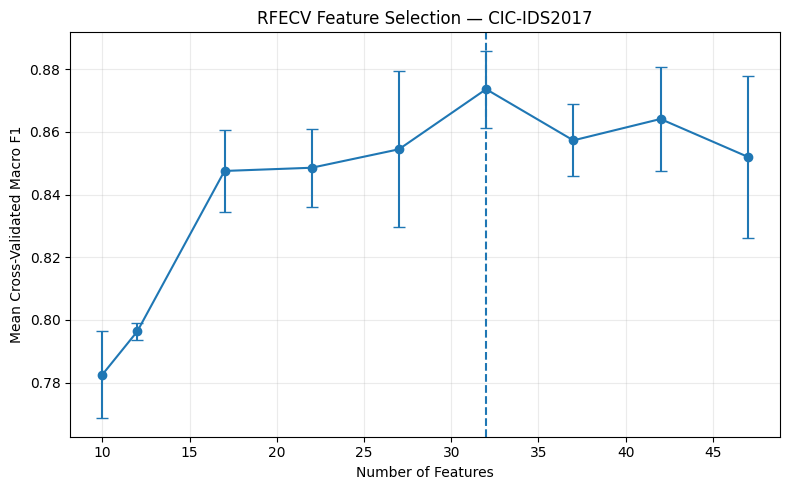


Saved artefacts:
Selected features : True
RFECV removed features : True
RFECV feature ranking : True
RFECV CV results : True
Feature-refinement audit : True
Feature-refinement summary : True
RFECV plot : True

Feature-selection artefacts saved successfully.


In [17]:
# Cell 17 — Save feature-selection artefacts

print(
    "Saving RF-F1 feature-selection artefacts..."
)

# --------------------------------------------------
# 1. Selected RFECV features
# --------------------------------------------------

SELECTED_FEATURES_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_selected_features.csv"
)

pd.DataFrame({
    "Feature":
        RF_F1_SELECTED_FEATURES
}).to_csv(
    SELECTED_FEATURES_PATH,
    index=False
)

# --------------------------------------------------
# 2. Features removed by RFECV
# --------------------------------------------------

RFECV_REMOVED_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_RFECV_removed_features.csv"
)

pd.DataFrame({
    "Feature":
        RFECV_REMOVED_FEATURES
}).to_csv(
    RFECV_REMOVED_PATH,
    index=False
)

# --------------------------------------------------
# 3. Complete RFECV ranking
# --------------------------------------------------

rfecv_ranking_df = pd.DataFrame({
    "Feature":
        CORRELATION_PRUNED_FEATURES,

    "Selected":
        rfecv_selector.support_,

    "RFECV Rank":
        rfecv_selector.ranking_
})

rfecv_ranking_df = (
    rfecv_ranking_df
    .sort_values(
        by=[
            "Selected",
            "RFECV Rank"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(
        drop=True
    )
)

RFECV_RANKING_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_RFECV_feature_ranking.csv"
)

rfecv_ranking_df.to_csv(
    RFECV_RANKING_PATH,
    index=False
)

# --------------------------------------------------
# 4. RFECV cross-validation results
# --------------------------------------------------

RFECV_RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_RFECV_cv_results.csv"
)

rfecv_cv_results_df.to_csv(
    RFECV_RESULTS_PATH,
    index=False
)

# --------------------------------------------------
# 5. Full feature-removal audit trail
# --------------------------------------------------

feature_audit_rows = []

for feature in FEATURE_COLS:

    if feature in CONSTANT_FEATURES:

        status = "Removed"
        stage = "Constant Removal"

    elif feature in CORRELATED_FEATURES_TO_REMOVE:

        status = "Removed"
        stage = "Correlation Pruning"

    elif feature in RFECV_REMOVED_FEATURES:

        status = "Removed"
        stage = "RFECV"

    elif feature in RF_F1_SELECTED_FEATURES:

        status = "Selected"
        stage = "Final RF-F1 Feature Set"

    else:

        status = "Review"
        stage = "Unclassified"

    feature_audit_rows.append({
        "Feature": feature,
        "Status": status,
        "Stage": stage
    })

feature_audit_df = pd.DataFrame(
    feature_audit_rows
)

FEATURE_AUDIT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_feature_refinement_audit.csv"
)

feature_audit_df.to_csv(
    FEATURE_AUDIT_PATH,
    index=False
)

# --------------------------------------------------
# 6. Summary
# --------------------------------------------------

feature_refinement_summary_df = pd.DataFrame({
    "Measure": [
        "Original Features",
        "Constant Features Removed",
        "After Constant Removal",
        "Correlated Features Removed",
        "After Correlation Pruning",
        "RFECV Features Removed",
        "Final Selected Features",
        "Overall Reduction Percentage",
        "RFECV Development Observations",
        "RFECV Folds",
        "RFECV Step",
        "RFECV Selector Trees",
        "RFECV Optimal Macro F1",
        "RFECV Macro F1 Std",
        "RFECV Runtime Seconds"
    ],

    "Value": [
        len(FEATURE_COLS),
        len(CONSTANT_FEATURES),
        len(NON_CONSTANT_FEATURES),
        len(
            CORRELATED_FEATURES_TO_REMOVE
        ),
        len(
            CORRELATION_PRUNED_FEATURES
        ),
        len(
            RFECV_REMOVED_FEATURES
        ),
        len(
            RF_F1_SELECTED_FEATURES
        ),
        round(
            reduction_percentage,
            4
        ),
        len(
            X_rfecv
        ),
        RFECV_FOLDS,
        RFECV_STEP,
        RFECV_SELECTOR_TREES,
        BEST_RFECV_MACRO_F1,
        BEST_RFECV_STD,
        RFECV_ELAPSED_SECONDS
    ]
})

FEATURE_SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_feature_refinement_summary.csv"
)

feature_refinement_summary_df.to_csv(
    FEATURE_SUMMARY_PATH,
    index=False
)

# --------------------------------------------------
# 7. RFECV performance plot
# --------------------------------------------------

RFECV_PLOT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_RFECV_macro_f1_vs_features.png"
)

plot_df = (
    rfecv_cv_results_df
    .sort_values(
        "Number of Features"
    )
)

plt.figure(
    figsize=(8, 5)
)

plt.errorbar(
    plot_df[
        "Number of Features"
    ],
    plot_df[
        "Mean Validation Macro F1"
    ],
    yerr=plot_df[
        "Std Validation Macro F1"
    ],
    marker="o",
    capsize=4
)

plt.axvline(
    x=BEST_RFECV_FEATURE_COUNT,
    linestyle="--"
)

plt.xlabel(
    "Number of Features"
)

plt.ylabel(
    "Mean Cross-Validated Macro F1"
)

plt.title(
    "RFECV Feature Selection — CIC-IDS2017"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    RFECV_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 8. Verify artefacts
# --------------------------------------------------

artefact_paths = {
    "Selected features":
        SELECTED_FEATURES_PATH,

    "RFECV removed features":
        RFECV_REMOVED_PATH,

    "RFECV feature ranking":
        RFECV_RANKING_PATH,

    "RFECV CV results":
        RFECV_RESULTS_PATH,

    "Feature-refinement audit":
        FEATURE_AUDIT_PATH,

    "Feature-refinement summary":
        FEATURE_SUMMARY_PATH,

    "RFECV plot":
        RFECV_PLOT_PATH
}

print(
    "\nSaved artefacts:"
)

for name, path in artefact_paths.items():

    print(
        name,
        ":",
        os.path.exists(
            path
        )
    )

print(
    "\nFeature-selection artefacts saved successfully."
)

In [18]:
# Cell 18 — Build refined TF-DF datasets
# using the LOCKED 32-feature subset

print(
    "Preparing RF-F1-CIC datasets..."
)

RF_F1_COLUMNS = (
    RF_F1_SELECTED_FEATURES
    + [LABEL_COL]
)

# --------------------------------------------------
# 1. Create reduced pandas datasets
# --------------------------------------------------

train_f1_df = (
    train_df[
        RF_F1_COLUMNS
    ]
    .copy()
)

val_f1_df = (
    val_df[
        RF_F1_COLUMNS
    ]
    .copy()
)

test_f1_df = (
    test_df[
        RF_F1_COLUMNS
    ]
    .copy()
)

print(
    "\nReduced dataset shapes:"
)

print(
    "Train:",
    train_f1_df.shape
)

print(
    "Validation:",
    val_f1_df.shape
)

print(
    "Test:",
    test_f1_df.shape
)

# --------------------------------------------------
# 2. Integrity checks
# --------------------------------------------------

assert train_f1_df.shape == (
    1_764_554,
    33
)

assert val_f1_df.shape == (
    378_119,
    33
)

assert test_f1_df.shape == (
    378_119,
    33
)

assert (
    list(
        train_f1_df.columns[:-1]
    )
    == RF_F1_SELECTED_FEATURES
)

assert (
    list(
        val_f1_df.columns[:-1]
    )
    == RF_F1_SELECTED_FEATURES
)

assert (
    list(
        test_f1_df.columns[:-1]
    )
    == RF_F1_SELECTED_FEATURES
)

assert (
    train_f1_df.columns[-1]
    == LABEL_COL
)

assert (
    train_f1_df.isna()
    .sum()
    .sum()
    == 0
)

assert (
    val_f1_df.isna()
    .sum()
    .sum()
    == 0
)

assert (
    test_f1_df.isna()
    .sum()
    .sum()
    == 0
)

print(
    "\nRefined dataset integrity checks: PASSED"
)

print(
    "Locked predictor count:",
    len(
        RF_F1_SELECTED_FEATURES
    )
)

# --------------------------------------------------
# 3. Release feature-selection objects
#    no longer needed for model training
# --------------------------------------------------

objects_to_delete = [
    "X_rfecv",
    "y_rfecv",
    "rfecv_df",
    "correlation_matrix",
    "numeric_array"
]

for object_name in objects_to_delete:

    if object_name in globals():

        del globals()[
            object_name
        ]

gc.collect()

print(
    "\nUnused feature-selection objects released."
)

# --------------------------------------------------
# 4. Convert to TensorFlow Decision Forest datasets
# --------------------------------------------------

print(
    "\nConverting refined datasets to TF-DF format..."
)

train_f1_tf = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        train_f1_df,
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

val_f1_tf = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        val_f1_df,
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

test_f1_tf = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        test_f1_df,
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

print(
    "\nTF-DF datasets created successfully."
)

print(
    "\nRF-F1-CIC is ready for training."
)

Preparing RF-F1-CIC datasets...

Reduced dataset shapes:
Train: (1764554, 33)
Validation: (378119, 33)
Test: (378119, 33)

Refined dataset integrity checks: PASSED
Locked predictor count: 32

Unused feature-selection objects released.

Converting refined datasets to TF-DF format...



TF-DF datasets created successfully.

RF-F1-CIC is ready for training.


In [19]:
# Cell 19 — Train RF-F1-CIC
# Frozen RF-H2 configuration + locked refined features

print(
    "Training RF-F1-CIC..."
)

print(
    "\nConfiguration:"
)

print(
    "Input features:",
    len(
        RF_F1_SELECTED_FEATURES
    )
)

print(
    "Trees:",
    BEST_TUNED_TREES
)

print(
    "Maximum depth:",
    BEST_TUNED_MAX_DEPTH
)

print(
    "Minimum examples:",
    BEST_TUNED_MIN_EXAMPLES
)

print(
    "Random seed:",
    BEST_TUNED_RANDOM_SEED
)

print(
    "CPU threads:",
    8
)

# --------------------------------------------------
# 1. Define model
# --------------------------------------------------

rf_f1_model = (
    tfdf.keras.RandomForestModel(
        task=tfdf.keras.Task.CLASSIFICATION,

        num_trees=
            BEST_TUNED_TREES,

        max_depth=
            BEST_TUNED_MAX_DEPTH,

        min_examples=
            BEST_TUNED_MIN_EXAMPLES,

        random_seed=
            BEST_TUNED_RANDOM_SEED,

        bootstrap_training_dataset=True,

        compute_oob_performances=True,

        num_threads=8,

        verbose=2
    )
)

# --------------------------------------------------
# 2. Train
# --------------------------------------------------

training_start = time.time()

rf_f1_model.fit(
    train_f1_tf,
    verbose=2
)

RF_F1_TRAIN_TIME = (
    time.time()
    - training_start
)

print(
    "\nRF-F1-CIC TRAINING COMPLETE"
)

print(
    "\nTraining time:"
)

print(
    round(
        RF_F1_TRAIN_TIME,
        6
    ),
    "seconds"
)

print(
    round(
        RF_F1_TRAIN_TIME / 60,
        2
    ),
    "minutes"
)

# --------------------------------------------------
# 3. Inspect trained forest
# --------------------------------------------------

rf_f1_inspector = (
    rf_f1_model
    .make_inspector()
)

print(
    "\nModel type:"
)

print(
    rf_f1_inspector.model_type()
)

print(
    "\nNumber of trees:"
)

print(
    rf_f1_inspector.num_trees()
)

print(
    "\nNumber of input features used:"
)

used_features = (
    rf_f1_inspector
    .features()
)

print(
    len(
        used_features
    )
)

# --------------------------------------------------
# 4. OOB evaluation
# --------------------------------------------------

rf_f1_oob = (
    rf_f1_inspector
    .evaluation()
)

print(
    "\nOOB evaluation:"
)

print(
    rf_f1_oob
)

# --------------------------------------------------
# 5. Training summary
# --------------------------------------------------

print(
    "\nRF-F1-CIC training summary"
)

print(
    "Input features:",
    len(
        RF_F1_SELECTED_FEATURES
    )
)

print(
    "Trees:",
    BEST_TUNED_TREES
)

print(
    "Max depth:",
    BEST_TUNED_MAX_DEPTH
)

print(
    "Min examples:",
    BEST_TUNED_MIN_EXAMPLES
)

print(
    "Training time:",
    round(
        RF_F1_TRAIN_TIME,
        6
    ),
    "seconds"
)

print(
    "\nDo NOT evaluate the held-out test set yet."
)

Training RF-F1-CIC...

Configuration:
Input features: 32
Trees: 100
Maximum depth: 30
Minimum examples: 1
Random seed: 42
CPU threads: 8
Use /tmp/tmpokal9faj as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_5:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Flow_Bytes/s': <tf.Tensor 'data_8:0' shape=(None,) dtype=float64>, 'Flow_Packets/s': <tf.Tensor 'data_9:0' shape=(None,) dtype=float64>, 'Fl

I0000 00:00:1791480462.525163     394 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1791480462.525432     394 kernel.cc:783] Collect training examples
I0000 00:00:1791480462.525445     394 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1791480462.525919     394 kernel.cc:401] Number of batches: 1765
I0000 00:00:1791480462.525930     394 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1791480462.935046     394 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 33

Number of columns by type:
	NUMERICAL: 32 (96.9697%)
	CATEGORICAL: 1 (3.0303%)

Columns:

NUMERICAL: 32 (96.9697%)
	0: "ACK_Flag_Coun

Model trained in 0:02:37.060443
Compiling model...
Model compiled.

RF-F1-CIC TRAINING COMPLETE

Training time:
189.713104 seconds
3.16 minutes

Model type:
RANDOM_FOREST

Number of trees:
100

Number of input features used:
32

OOB evaluation:
Evaluation(num_examples=1764554, accuracy=0.9986410163701422, loss=0.01638411243918306, rmse=None, ndcg=None, aucs=None, auuc=None, qini=None)

RF-F1-CIC training summary
Input features: 32
Trees: 100
Max depth: 30
Min examples: 1
Training time: 189.713104 seconds

Do NOT evaluate the held-out test set yet.


In [20]:
# Cell 20 — RF-F1-CIC validation evaluation

print(
    "Evaluating RF-F1-CIC on frozen validation set..."
)

# --------------------------------------------------
# 1. Generate validation probabilities
# --------------------------------------------------

validation_start = time.time()

rf_f1_val_prob = (
    rf_f1_model.predict(
        val_f1_tf,
        verbose=0
    )
)

RF_F1_VAL_PREDICTION_TIME = (
    time.time()
    - validation_start
)

print(
    "\nPrediction matrix shape:",
    rf_f1_val_prob.shape
)

assert (
    rf_f1_val_prob.shape[0]
    == len(val_f1_df)
)

assert (
    rf_f1_val_prob.shape[1]
    == len(CLASS_NAMES)
)

# --------------------------------------------------
# 2. Convert probability output to class labels
# --------------------------------------------------

rf_f1_val_pred_idx = np.argmax(
    rf_f1_val_prob,
    axis=1
)

rf_f1_val_pred = np.array(
    CLASS_NAMES
)[
    rf_f1_val_pred_idx
]

rf_f1_val_true = (
    val_f1_df[
        LABEL_COL
    ]
    .to_numpy()
)

# --------------------------------------------------
# 3. Sanity checks
# --------------------------------------------------

print(
    "\nValidation observations:",
    len(
        rf_f1_val_true
    )
)

print(
    "Predicted observations:",
    len(
        rf_f1_val_pred
    )
)

print(
    "Unique predicted classes:",
    len(
        np.unique(
            rf_f1_val_pred
        )
    )
)

print(
    "Prediction time:",
    round(
        RF_F1_VAL_PREDICTION_TIME,
        3
    ),
    "seconds"
)

# --------------------------------------------------
# 4. Calculate validation metrics
# --------------------------------------------------

RF_F1_VAL_ACCURACY = accuracy_score(
    rf_f1_val_true,
    rf_f1_val_pred
)

RF_F1_VAL_MACRO_PRECISION = precision_score(
    rf_f1_val_true,
    rf_f1_val_pred,
    average="macro",
    zero_division=0
)

RF_F1_VAL_MACRO_RECALL = recall_score(
    rf_f1_val_true,
    rf_f1_val_pred,
    average="macro",
    zero_division=0
)

RF_F1_VAL_MACRO_F1 = f1_score(
    rf_f1_val_true,
    rf_f1_val_pred,
    average="macro",
    zero_division=0
)

RF_F1_VAL_WEIGHTED_F1 = f1_score(
    rf_f1_val_true,
    rf_f1_val_pred,
    average="weighted",
    zero_division=0
)

RF_F1_VAL_BALANCED_ACCURACY = (
    balanced_accuracy_score(
        rf_f1_val_true,
        rf_f1_val_pred
    )
)

RF_F1_VAL_MCC = matthews_corrcoef(
    rf_f1_val_true,
    rf_f1_val_pred
)

# --------------------------------------------------
# 5. Display RF-F1 validation result
# --------------------------------------------------

print(
    "\nRF-F1-CIC VALIDATION RESULTS"
)

print(
    "Accuracy:",
    round(
        RF_F1_VAL_ACCURACY,
        6
    )
)

print(
    "Macro Precision:",
    round(
        RF_F1_VAL_MACRO_PRECISION,
        6
    )
)

print(
    "Macro Recall:",
    round(
        RF_F1_VAL_MACRO_RECALL,
        6
    )
)

print(
    "Macro F1:",
    round(
        RF_F1_VAL_MACRO_F1,
        6
    )
)

print(
    "Weighted F1:",
    round(
        RF_F1_VAL_WEIGHTED_F1,
        6
    )
)

print(
    "Balanced Accuracy:",
    round(
        RF_F1_VAL_BALANCED_ACCURACY,
        6
    )
)

print(
    "MCC:",
    round(
        RF_F1_VAL_MCC,
        6
    )
)

# --------------------------------------------------
# 6. Compare with frozen RF-H2 validation result
# --------------------------------------------------

RF_H2_VAL_MACRO_F1 = float(
    best_tuning_df.iloc[0][
        "Validation Macro F1"
    ]
)

RF_F1_VS_H2_VAL_DELTA = (
    RF_F1_VAL_MACRO_F1
    - RF_H2_VAL_MACRO_F1
)

print(
    "\nValidation comparison"
)

print(
    "RF-H2 Macro F1:",
    round(
        RF_H2_VAL_MACRO_F1,
        6
    )
)

print(
    "RF-F1 Macro F1:",
    round(
        RF_F1_VAL_MACRO_F1,
        6
    )
)

print(
    "Absolute change:",
    round(
        RF_F1_VS_H2_VAL_DELTA,
        6
    )
)

print(
    "Relative change:",
    round(
        (
            RF_F1_VS_H2_VAL_DELTA
            / RF_H2_VAL_MACRO_F1
        ) * 100,
        4
    ),
    "%"
)

if RF_F1_VS_H2_VAL_DELTA > 0:

    print(
        "\nRF-F1 improves validation Macro F1 "
        "relative to RF-H2."
    )

elif RF_F1_VS_H2_VAL_DELTA < 0:

    print(
        "\nRF-F1 has lower validation Macro F1 "
        "than RF-H2."
    )

else:

    print(
        "\nRF-F1 matches RF-H2 validation Macro F1."
    )

print(
    "\nHeld-out test set remains untouched."
)

Evaluating RF-F1-CIC on frozen validation set...

Prediction matrix shape: (378119, 15)

Validation observations: 378119
Predicted observations: 378119
Unique predicted classes: 15
Prediction time: 7.866 seconds

RF-F1-CIC VALIDATION RESULTS
Accuracy: 0.998622
Macro Precision: 0.937828
Macro Recall: 0.811222
Macro F1: 0.847499
Weighted F1: 0.99857
Balanced Accuracy: 0.811222
MCC: 0.995418

Validation comparison
RF-H2 Macro F1: 0.881331
RF-F1 Macro F1: 0.847499
Absolute change: -0.033832
Relative change: -3.8388 %

RF-F1 has lower validation Macro F1 than RF-H2.

Held-out test set remains untouched.


In [21]:
# Cell 21 — Save RF-F1 validation result
# and lock feature-refinement decision

print(
    "Saving RF-F1-CIC validation result..."
)

# --------------------------------------------------
# 1. RF-F1 validation metrics
# --------------------------------------------------

rf_f1_validation_metrics_df = pd.DataFrame({
    "Model": [
        "RF-F1-CIC"
    ],

    "Input Features": [
        len(
            RF_F1_SELECTED_FEATURES
        )
    ],

    "Trees": [
        BEST_TUNED_TREES
    ],

    "Max Depth": [
        BEST_TUNED_MAX_DEPTH
    ],

    "Min Examples": [
        BEST_TUNED_MIN_EXAMPLES
    ],

    "Accuracy": [
        RF_F1_VAL_ACCURACY
    ],

    "Macro Precision": [
        RF_F1_VAL_MACRO_PRECISION
    ],

    "Macro Recall": [
        RF_F1_VAL_MACRO_RECALL
    ],

    "Macro F1": [
        RF_F1_VAL_MACRO_F1
    ],

    "Weighted F1": [
        RF_F1_VAL_WEIGHTED_F1
    ],

    "Balanced Accuracy": [
        RF_F1_VAL_BALANCED_ACCURACY
    ],

    "MCC": [
        RF_F1_VAL_MCC
    ],

    "Training Time Seconds": [
        RF_F1_TRAIN_TIME
    ],

    "Prediction Time Seconds": [
        RF_F1_VAL_PREDICTION_TIME
    ]
})

RF_F1_VALIDATION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_CIC_validation.csv"
)

rf_f1_validation_metrics_df.to_csv(
    RF_F1_VALIDATION_PATH,
    index=False
)

# --------------------------------------------------
# 2. RF-H2 vs RF-F1 validation comparison
# --------------------------------------------------

rf_h2_vs_f1_validation_df = pd.DataFrame({
    "Model": [
        "RF-H2-CIC",
        "RF-F1-CIC"
    ],

    "Input Features": [
        78,
        len(
            RF_F1_SELECTED_FEATURES
        )
    ],

    "Validation Macro F1": [
        RF_H2_VAL_MACRO_F1,
        RF_F1_VAL_MACRO_F1
    ]
})

RF_H2_VS_F1_VALIDATION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_vs_RF_F1_validation_comparison.csv"
)

rf_h2_vs_f1_validation_df.to_csv(
    RF_H2_VS_F1_VALIDATION_PATH,
    index=False
)

# --------------------------------------------------
# 3. Lock feature-refinement decision
# --------------------------------------------------

if (
    RF_F1_VAL_MACRO_F1
    > RF_H2_VAL_MACRO_F1
):

    FEATURE_REFINEMENT_SELECTED = True

    FEATURE_REFINEMENT_DECISION = (
        "RF-F1 selected for integration because "
        "validation Macro F1 improved over RF-H2."
    )

else:

    FEATURE_REFINEMENT_SELECTED = False

    FEATURE_REFINEMENT_DECISION = (
        "RF-F1 not selected over RF-H2 because "
        "validation Macro F1 decreased. "
        "Feature refinement is retained as an "
        "experimental ablation result only."
    )

feature_refinement_decision_df = pd.DataFrame({
    "Baseline Tuned Model": [
        "RF-H2-CIC"
    ],

    "Feature-Refined Model": [
        "RF-F1-CIC"
    ],

    "RF-H2 Validation Macro F1": [
        RF_H2_VAL_MACRO_F1
    ],

    "RF-F1 Validation Macro F1": [
        RF_F1_VAL_MACRO_F1
    ],

    "Absolute Delta": [
        RF_F1_VS_H2_VAL_DELTA
    ],

    "Relative Delta Percent": [
        (
            RF_F1_VS_H2_VAL_DELTA
            / RF_H2_VAL_MACRO_F1
        ) * 100
    ],

    "Feature Refinement Selected": [
        FEATURE_REFINEMENT_SELECTED
    ],

    "Decision": [
        FEATURE_REFINEMENT_DECISION
    ]
})

FEATURE_REFINEMENT_DECISION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_feature_refinement_decision.csv"
)

feature_refinement_decision_df.to_csv(
    FEATURE_REFINEMENT_DECISION_PATH,
    index=False
)

# --------------------------------------------------
# 4. Display locked decision
# --------------------------------------------------

print(
    "\nRF-H2 Validation Macro F1:",
    round(
        RF_H2_VAL_MACRO_F1,
        6
    )
)

print(
    "RF-F1 Validation Macro F1:",
    round(
        RF_F1_VAL_MACRO_F1,
        6
    )
)

print(
    "Absolute delta:",
    round(
        RF_F1_VS_H2_VAL_DELTA,
        6
    )
)

print(
    "Feature refinement selected:",
    FEATURE_REFINEMENT_SELECTED
)

print(
    "\nDecision:"
)

print(
    FEATURE_REFINEMENT_DECISION
)

# --------------------------------------------------
# 5. Verify saved artefacts
# --------------------------------------------------

print(
    "\nSaved artefacts:"
)

print(
    "RF-F1 validation metrics:",
    os.path.exists(
        RF_F1_VALIDATION_PATH
    )
)

print(
    "RF-H2 vs RF-F1 comparison:",
    os.path.exists(
        RF_H2_VS_F1_VALIDATION_PATH
    )
)

print(
    "Feature-refinement decision:",
    os.path.exists(
        FEATURE_REFINEMENT_DECISION_PATH
    )
)

print(
    "\nRF-F1 validation stage COMPLETE AND LOCKED."
)

print(
    "Held-out test set remains untouched."
)

Saving RF-F1-CIC validation result...

RF-H2 Validation Macro F1: 0.881331
RF-F1 Validation Macro F1: 0.847499
Absolute delta: -0.033832
Feature refinement selected: False

Decision:
RF-F1 not selected over RF-H2 because validation Macro F1 decreased. Feature refinement is retained as an experimental ablation result only.

Saved artefacts:
RF-F1 validation metrics: True
RF-H2 vs RF-F1 comparison: True
Feature-refinement decision: True

RF-F1 validation stage COMPLETE AND LOCKED.
Held-out test set remains untouched.


In [22]:
# Cell 22 — Save RF-F1-CIC model and configuration

print(
    "Saving RF-F1-CIC model and configuration..."
)

# --------------------------------------------------
# 1. Model save path
# --------------------------------------------------

RF_F1_SAVED_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "saved_model"
)

# Remove an incomplete previous export if present
if os.path.exists(
    RF_F1_SAVED_MODEL_PATH
):

    import shutil

    shutil.rmtree(
        RF_F1_SAVED_MODEL_PATH
    )

# --------------------------------------------------
# 2. Save TensorFlow Decision Forest model
# --------------------------------------------------

rf_f1_model.save(
    RF_F1_SAVED_MODEL_PATH
)

print(
    "\nModel saved to:"
)

print(
    RF_F1_SAVED_MODEL_PATH
)

# --------------------------------------------------
# 3. Save exact RF-F1 configuration
# --------------------------------------------------

rf_f1_configuration_df = pd.DataFrame({
    "Parameter": [
        "Model",
        "Parent Tuned Configuration",
        "Number of Trees",
        "Maximum Depth",
        "Minimum Examples",
        "Random Seed",
        "Input Features",
        "Original Features",
        "Feature Reduction Percent",
        "Feature Selection Method",
        "Correlation Threshold",
        "RFECV Development Size",
        "RFECV Folds",
        "RFECV Step",
        "RFECV Selection Metric",
        "RFECV Mean Macro F1",
        "RFECV Macro F1 Std",
        "Training Time Seconds",
        "OOB Accuracy",
        "OOB Log Loss",
        "Validation Macro F1",
        "Feature Refinement Selected"
    ],

    "Value": [
        "RF-F1-CIC",
        "RF-H2-CIC",
        BEST_TUNED_TREES,
        BEST_TUNED_MAX_DEPTH,
        BEST_TUNED_MIN_EXAMPLES,
        BEST_TUNED_RANDOM_SEED,
        len(
            RF_F1_SELECTED_FEATURES
        ),
        len(
            FEATURE_COLS
        ),
        round(
            reduction_percentage,
            4
        ),
        (
            "Constant removal + "
            "correlation pruning + RFECV"
        ),
        CORRELATION_THRESHOLD,
        200_042,
        RFECV_FOLDS,
        RFECV_STEP,
        "Macro F1",
        BEST_RFECV_MACRO_F1,
        BEST_RFECV_STD,
        RF_F1_TRAIN_TIME,
        rf_f1_oob.accuracy,
        rf_f1_oob.loss,
        RF_F1_VAL_MACRO_F1,
        FEATURE_REFINEMENT_SELECTED
    ]
})

RF_F1_CONFIGURATION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_CIC_configuration.csv"
)

rf_f1_configuration_df.to_csv(
    RF_F1_CONFIGURATION_PATH,
    index=False
)

# --------------------------------------------------
# 4. Save locked final feature list beside config
# --------------------------------------------------

RF_F1_LOCKED_FEATURES_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_CIC_locked_features.csv"
)

pd.DataFrame({
    "Feature Number":
        np.arange(
            1,
            len(
                RF_F1_SELECTED_FEATURES
            ) + 1
        ),

    "Feature":
        RF_F1_SELECTED_FEATURES
}).to_csv(
    RF_F1_LOCKED_FEATURES_PATH,
    index=False
)

# --------------------------------------------------
# 5. Verify artefacts
# --------------------------------------------------

print(
    "\nSaved artefact checks:"
)

print(
    "Saved model:",
    os.path.exists(
        RF_F1_SAVED_MODEL_PATH
    )
)

print(
    "Configuration CSV:",
    os.path.exists(
        RF_F1_CONFIGURATION_PATH
    )
)

print(
    "Locked feature list:",
    os.path.exists(
        RF_F1_LOCKED_FEATURES_PATH
    )
)

print(
    "\nRF-F1-CIC model and configuration saved."
)

print(
    "\nImportant:"
)

print(
    "Feature refinement remains NOT SELECTED "
    "for integration."
)

print(
    "The held-out test set has still not been "
    "used for the selection decision."
)

Saving RF-F1-CIC model and configuration...



Model saved to:
/content/drive/MyDrive/MSc_Project/models/RF_F1_CIC/saved_model

Saved artefact checks:
Saved model: True
Configuration CSV: True
Locked feature list: True

RF-F1-CIC model and configuration saved.

Important:
Feature refinement remains NOT SELECTED for integration.
The held-out test set has still not been used for the selection decision.


In [23]:
# Cell 23 — RF-F1-CIC held-out test evaluation
# Final reporting only — NOT used for model selection

print(
    "Evaluating RF-F1-CIC on held-out test set..."
)

print(
    "\nIMPORTANT:"
)

print(
    "RF-F1 was already rejected for integration "
    "using validation Macro F1."
)

print(
    "This test evaluation is for final reporting only."
)

# --------------------------------------------------
# 1. Generate test predictions
# --------------------------------------------------

test_prediction_start = time.time()

rf_f1_test_prob = (
    rf_f1_model.predict(
        test_f1_tf,
        verbose=0
    )
)

RF_F1_TEST_PREDICTION_TIME = (
    time.time()
    - test_prediction_start
)

print(
    "\nPrediction matrix shape:",
    rf_f1_test_prob.shape
)

assert (
    rf_f1_test_prob.shape[0]
    == len(test_f1_df)
)

assert (
    rf_f1_test_prob.shape[1]
    == len(CLASS_NAMES)
)

# --------------------------------------------------
# 2. Convert probabilities to class predictions
# --------------------------------------------------

rf_f1_test_pred_idx = np.argmax(
    rf_f1_test_prob,
    axis=1
)

rf_f1_test_pred = np.array(
    CLASS_NAMES
)[
    rf_f1_test_pred_idx
]

rf_f1_test_true = (
    test_f1_df[
        LABEL_COL
    ]
    .to_numpy()
)

# --------------------------------------------------
# 3. Sanity checks
# --------------------------------------------------

print(
    "\nTest observations:",
    len(
        rf_f1_test_true
    )
)

print(
    "Predicted observations:",
    len(
        rf_f1_test_pred
    )
)

print(
    "Unique predicted classes:",
    len(
        np.unique(
            rf_f1_test_pred
        )
    )
)

print(
    "Prediction time:",
    round(
        RF_F1_TEST_PREDICTION_TIME,
        3
    ),
    "seconds"
)

# --------------------------------------------------
# 4. Calculate final test metrics
# --------------------------------------------------

RF_F1_TEST_ACCURACY = accuracy_score(
    rf_f1_test_true,
    rf_f1_test_pred
)

RF_F1_TEST_MACRO_PRECISION = precision_score(
    rf_f1_test_true,
    rf_f1_test_pred,
    average="macro",
    zero_division=0
)

RF_F1_TEST_MACRO_RECALL = recall_score(
    rf_f1_test_true,
    rf_f1_test_pred,
    average="macro",
    zero_division=0
)

RF_F1_TEST_MACRO_F1 = f1_score(
    rf_f1_test_true,
    rf_f1_test_pred,
    average="macro",
    zero_division=0
)

RF_F1_TEST_WEIGHTED_F1 = f1_score(
    rf_f1_test_true,
    rf_f1_test_pred,
    average="weighted",
    zero_division=0
)

RF_F1_TEST_BALANCED_ACCURACY = (
    balanced_accuracy_score(
        rf_f1_test_true,
        rf_f1_test_pred
    )
)

RF_F1_TEST_MCC = matthews_corrcoef(
    rf_f1_test_true,
    rf_f1_test_pred
)

# --------------------------------------------------
# 5. Display final test result
# --------------------------------------------------

print(
    "\nRF-F1-CIC HELD-OUT TEST RESULTS"
)

print(
    "Accuracy:",
    round(
        RF_F1_TEST_ACCURACY,
        6
    )
)

print(
    "Macro Precision:",
    round(
        RF_F1_TEST_MACRO_PRECISION,
        6
    )
)

print(
    "Macro Recall:",
    round(
        RF_F1_TEST_MACRO_RECALL,
        6
    )
)

print(
    "Macro F1:",
    round(
        RF_F1_TEST_MACRO_F1,
        6
    )
)

print(
    "Weighted F1:",
    round(
        RF_F1_TEST_WEIGHTED_F1,
        6
    )
)

print(
    "Balanced Accuracy:",
    round(
        RF_F1_TEST_BALANCED_ACCURACY,
        6
    )
)

print(
    "MCC:",
    round(
        RF_F1_TEST_MCC,
        6
    )
)

# --------------------------------------------------
# 6. Compare validation and test behaviour
# --------------------------------------------------

print(
    "\nValidation vs Test Macro F1"
)

print(
    "Validation Macro F1:",
    round(
        RF_F1_VAL_MACRO_F1,
        6
    )
)

print(
    "Test Macro F1:",
    round(
        RF_F1_TEST_MACRO_F1,
        6
    )
)

print(
    "Difference:",
    round(
        RF_F1_TEST_MACRO_F1
        - RF_F1_VAL_MACRO_F1,
        6
    )
)

print(
    "\nFeature-refinement selection decision remains:"
)

print(
    FEATURE_REFINEMENT_DECISION
)

Evaluating RF-F1-CIC on held-out test set...

IMPORTANT:
RF-F1 was already rejected for integration using validation Macro F1.
This test evaluation is for final reporting only.

Prediction matrix shape: (378119, 15)

Test observations: 378119
Predicted observations: 378119
Unique predicted classes: 15
Prediction time: 7.973 seconds

RF-F1-CIC HELD-OUT TEST RESULTS
Accuracy: 0.998744
Macro Precision: 0.918782
Macro Recall: 0.921449
Macro F1: 0.915179
Weighted F1: 0.998698
Balanced Accuracy: 0.921449
MCC: 0.995823

Validation vs Test Macro F1
Validation Macro F1: 0.847499
Test Macro F1: 0.915179
Difference: 0.06768

Feature-refinement selection decision remains:
RF-F1 not selected over RF-H2 because validation Macro F1 decreased. Feature refinement is retained as an experimental ablation result only.


In [24]:
# Cell 24 — RF-F1-CIC held-out test classification report

print(
    "Generating RF-F1-CIC classification report..."
)

# --------------------------------------------------
# 1. Generate classification report
# --------------------------------------------------

rf_f1_test_report_dict = classification_report(
    rf_f1_test_true,
    rf_f1_test_pred,
    labels=CLASS_NAMES,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

rf_f1_test_report_df = (
    pd.DataFrame(
        rf_f1_test_report_dict
    )
    .transpose()
)

# --------------------------------------------------
# 2. Keep class rows separately
# --------------------------------------------------

rf_f1_per_class_df = (
    rf_f1_test_report_df
    .loc[
        CLASS_NAMES,
        [
            "precision",
            "recall",
            "f1-score",
            "support"
        ]
    ]
    .copy()
)

rf_f1_per_class_df[
    "support"
] = (
    rf_f1_per_class_df[
        "support"
    ]
    .astype(int)
)

print(
    "\nRF-F1-CIC PER-CLASS TEST RESULTS"
)

display(
    rf_f1_per_class_df
)

# --------------------------------------------------
# 3. Display aggregate report
# --------------------------------------------------

print(
    "\nAggregate rows:"
)

display(
    rf_f1_test_report_df.loc[
        [
            "accuracy",
            "macro avg",
            "weighted avg"
        ]
    ]
)

# --------------------------------------------------
# 4. Identify weakest classes by F1
# --------------------------------------------------

weakest_classes_df = (
    rf_f1_per_class_df
    .sort_values(
        by="f1-score",
        ascending=True
    )
)

print(
    "\nClasses ranked from lowest to highest F1:"
)

display(
    weakest_classes_df
)

# --------------------------------------------------
# 5. Save reports
# --------------------------------------------------

RF_F1_CLASS_REPORT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_CIC_classification_report.csv"
)

RF_F1_PER_CLASS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_CIC_per_class_metrics.csv"
)

rf_f1_test_report_df.to_csv(
    RF_F1_CLASS_REPORT_PATH
)

rf_f1_per_class_df.to_csv(
    RF_F1_PER_CLASS_PATH
)

print(
    "\nSaved artefacts:"
)

print(
    "Classification report:",
    os.path.exists(
        RF_F1_CLASS_REPORT_PATH
    )
)

print(
    "Per-class metrics:",
    os.path.exists(
        RF_F1_PER_CLASS_PATH
    )
)

Generating RF-F1-CIC classification report...

RF-F1-CIC PER-CLASS TEST RESULTS


,precision,recall,f1-score,support
BENIGN,0.999481,0.999399,0.999440,314258
Bot,0.923077,0.780822,0.846011,292
DDoS,0.999948,0.999896,0.999922,19202
DoS GoldenEye,0.998699,0.994815,0.996753,1543
DoS Hulk,0.998535,0.998804,0.998670,25927
DoS Slowhttptest,0.989861,0.996173,0.993007,784
DoS slowloris,0.995037,0.992574,0.993804,808
FTP-Patator,1.000000,0.996629,0.998312,890
Heartbleed,1.000000,1.000000,1.000000,1
Infiltration,1.000000,1.000000,1.000000,5



Aggregate rows:


,precision,recall,f1-score,support
accuracy,0.998744,0.998744,0.998744,0.998744
macro avg,0.918782,0.921449,0.915179,378119.000000
weighted avg,0.998693,0.998744,0.998698,378119.000000



Classes ranked from lowest to highest F1:


,precision,recall,f1-score,support
Web Attack - XSS,0.422222,0.193878,0.265734,98
Web Attack - Brute Force,0.714815,0.873303,0.786151,221
Bot,0.923077,0.780822,0.846011,292
Web Attack - SQL Injection,0.750000,1.000000,0.857143,3
PortScan,0.990057,0.995443,0.992742,13604
DoS Slowhttptest,0.989861,0.996173,0.993007,784
DoS slowloris,0.995037,0.992574,0.993804,808
DoS GoldenEye,0.998699,0.994815,0.996753,1543
FTP-Patator,1.000000,0.996629,0.998312,890
DoS Hulk,0.998535,0.998804,0.998670,25927



Saved artefacts:
Classification report: True
Per-class metrics: True


Generating RF-F1-CIC confusion matrices...

Confusion matrix shape: (15, 15)
Total observations represented: 378119


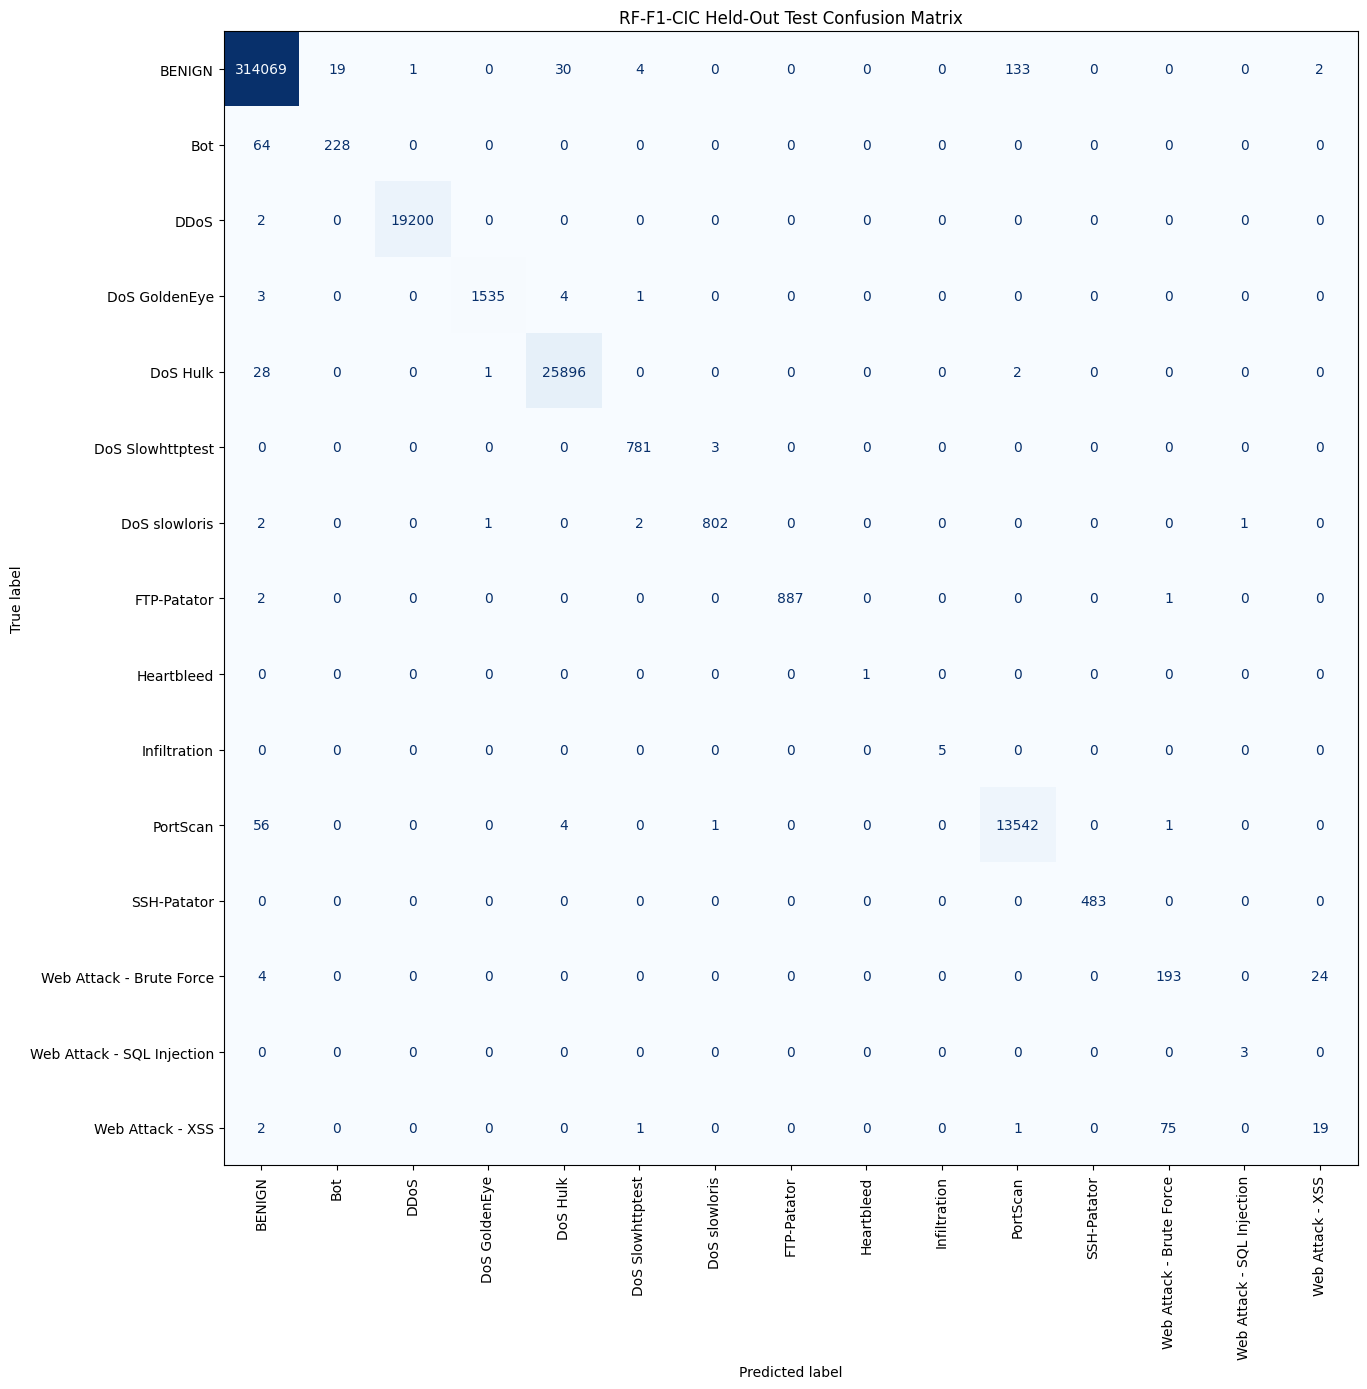

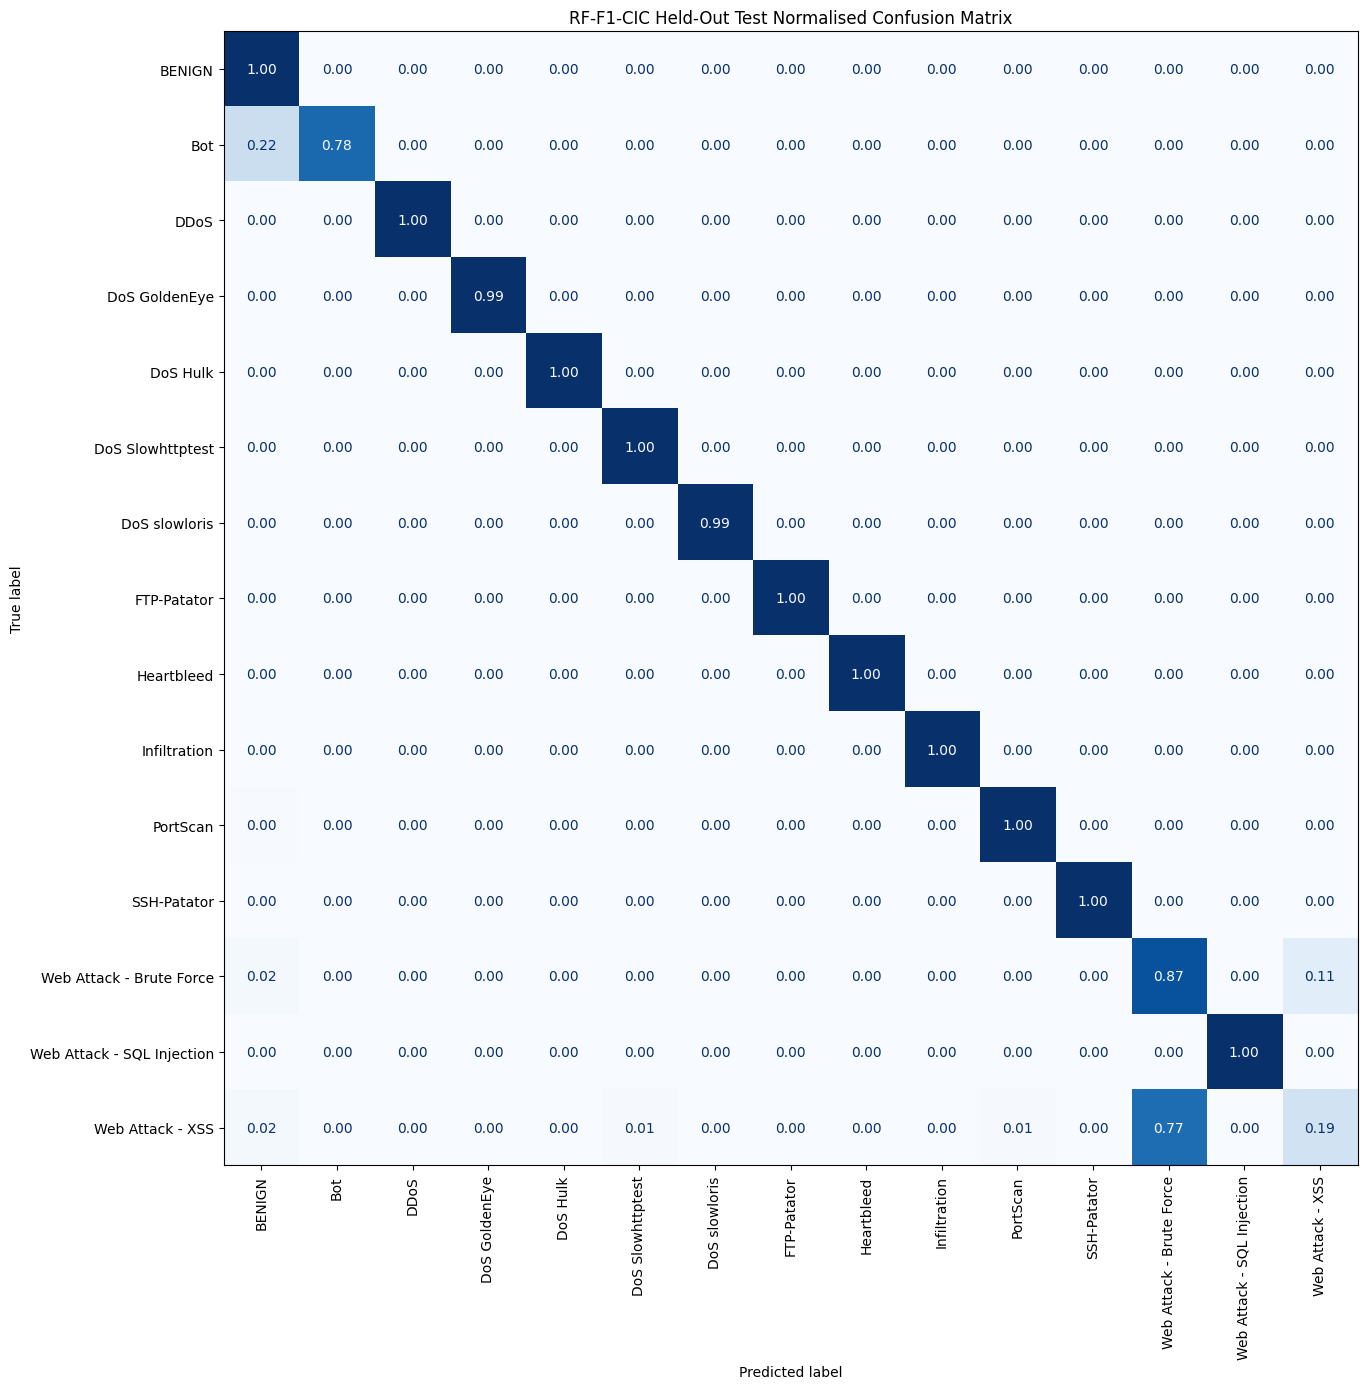


Saved artefacts:
Raw confusion matrix CSV: True
Raw confusion matrix PNG: True
Normalised confusion matrix PNG: True


In [25]:
# Cell 25 — RF-F1-CIC held-out test confusion matrices

print(
    "Generating RF-F1-CIC confusion matrices..."
)

# --------------------------------------------------
# 1. Raw confusion matrix
# --------------------------------------------------

rf_f1_confusion_matrix = confusion_matrix(
    rf_f1_test_true,
    rf_f1_test_pred,
    labels=CLASS_NAMES
)

assert rf_f1_confusion_matrix.shape == (
    len(CLASS_NAMES),
    len(CLASS_NAMES)
)

print(
    "\nConfusion matrix shape:",
    rf_f1_confusion_matrix.shape
)

print(
    "Total observations represented:",
    int(
        rf_f1_confusion_matrix.sum()
    )
)

# --------------------------------------------------
# 2. Save raw matrix as CSV
# --------------------------------------------------

rf_f1_confusion_df = pd.DataFrame(
    rf_f1_confusion_matrix,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

RF_F1_CONFUSION_CSV_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_CIC_confusion_matrix.csv"
)

rf_f1_confusion_df.to_csv(
    RF_F1_CONFUSION_CSV_PATH
)

# --------------------------------------------------
# 3. Plot raw-count confusion matrix
# --------------------------------------------------

RF_F1_CONFUSION_PNG_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_CIC_confusion_matrix.png"
)

fig, ax = plt.subplots(
    figsize=(16, 14)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_f1_confusion_matrix,
    display_labels=CLASS_NAMES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=90,
    colorbar=False
)

ax.set_title(
    "RF-F1-CIC Held-Out Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    RF_F1_CONFUSION_PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 4. Row-normalised confusion matrix
# --------------------------------------------------

rf_f1_confusion_normalized = confusion_matrix(
    rf_f1_test_true,
    rf_f1_test_pred,
    labels=CLASS_NAMES,
    normalize="true"
)

RF_F1_CONFUSION_NORMALIZED_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_CIC_confusion_matrix_normalized.png"
)

fig, ax = plt.subplots(
    figsize=(16, 14)
)

disp_norm = ConfusionMatrixDisplay(
    confusion_matrix=
        rf_f1_confusion_normalized,
    display_labels=CLASS_NAMES
)

disp_norm.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=90,
    colorbar=False
)

ax.set_title(
    "RF-F1-CIC Held-Out Test "
    "Normalised Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    RF_F1_CONFUSION_NORMALIZED_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 5. Artefact checks
# --------------------------------------------------

print(
    "\nSaved artefacts:"
)

print(
    "Raw confusion matrix CSV:",
    os.path.exists(
        RF_F1_CONFUSION_CSV_PATH
    )
)

print(
    "Raw confusion matrix PNG:",
    os.path.exists(
        RF_F1_CONFUSION_PNG_PATH
    )
)

print(
    "Normalised confusion matrix PNG:",
    os.path.exists(
        RF_F1_CONFUSION_NORMALIZED_PATH
    )
)

In [26]:
# Cell 26 — Save final RF-F1-CIC held-out test metrics

print(
    "Saving final RF-F1-CIC test metrics..."
)

# --------------------------------------------------
# 1. Final test metrics table
# --------------------------------------------------

rf_f1_final_metrics_df = pd.DataFrame({
    "Model": [
        "RF-F1-CIC"
    ],

    "Dataset": [
        "CIC-IDS2017"
    ],

    "Evaluation Split": [
        "Held-Out Test"
    ],

    "Input Features": [
        len(
            RF_F1_SELECTED_FEATURES
        )
    ],

    "Trees": [
        BEST_TUNED_TREES
    ],

    "Max Depth": [
        BEST_TUNED_MAX_DEPTH
    ],

    "Min Examples": [
        BEST_TUNED_MIN_EXAMPLES
    ],

    "Accuracy": [
        RF_F1_TEST_ACCURACY
    ],

    "Macro Precision": [
        RF_F1_TEST_MACRO_PRECISION
    ],

    "Macro Recall": [
        RF_F1_TEST_MACRO_RECALL
    ],

    "Macro F1": [
        RF_F1_TEST_MACRO_F1
    ],

    "Weighted F1": [
        RF_F1_TEST_WEIGHTED_F1
    ],

    "Balanced Accuracy": [
        RF_F1_TEST_BALANCED_ACCURACY
    ],

    "MCC": [
        RF_F1_TEST_MCC
    ],

    "Training Time Seconds": [
        RF_F1_TRAIN_TIME
    ],

    "Prediction Time Seconds": [
        RF_F1_TEST_PREDICTION_TIME
    ],

    "OOB Accuracy": [
        rf_f1_oob.accuracy
    ],

    "OOB Log Loss": [
        rf_f1_oob.loss
    ],

    "Validation Macro F1": [
        RF_F1_VAL_MACRO_F1
    ],

    "Feature Refinement Selected": [
        FEATURE_REFINEMENT_SELECTED
    ]
})

# --------------------------------------------------
# 2. Save final metrics
# --------------------------------------------------

RF_F1_FINAL_METRICS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_CIC_metrics.csv"
)

rf_f1_final_metrics_df.to_csv(
    RF_F1_FINAL_METRICS_PATH,
    index=False
)

# --------------------------------------------------
# 3. Save compact experiment summary
# --------------------------------------------------

rf_f1_experiment_summary_df = pd.DataFrame({
    "Measure": [
        "Original Features",
        "After Constant Removal",
        "After Correlation Pruning",
        "Final RFECV Features",
        "Feature Reduction Percent",
        "RFECV CV Macro F1",
        "Validation Macro F1",
        "Test Macro F1",
        "Test Accuracy",
        "Test Macro Recall",
        "Test Balanced Accuracy",
        "Test MCC",
        "OOB Accuracy",
        "Training Time Seconds",
        "Feature Refinement Selected"
    ],

    "Value": [
        len(FEATURE_COLS),
        len(NON_CONSTANT_FEATURES),
        len(
            CORRELATION_PRUNED_FEATURES
        ),
        len(
            RF_F1_SELECTED_FEATURES
        ),
        round(
            reduction_percentage,
            4
        ),
        BEST_RFECV_MACRO_F1,
        RF_F1_VAL_MACRO_F1,
        RF_F1_TEST_MACRO_F1,
        RF_F1_TEST_ACCURACY,
        RF_F1_TEST_MACRO_RECALL,
        RF_F1_TEST_BALANCED_ACCURACY,
        RF_F1_TEST_MCC,
        rf_f1_oob.accuracy,
        RF_F1_TRAIN_TIME,
        FEATURE_REFINEMENT_SELECTED
    ]
})

RF_F1_EXPERIMENT_SUMMARY_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_CIC_experiment_summary.csv"
)

rf_f1_experiment_summary_df.to_csv(
    RF_F1_EXPERIMENT_SUMMARY_PATH,
    index=False
)

# --------------------------------------------------
# 4. Display final result
# --------------------------------------------------

print(
    "\nRF-F1-CIC FINAL TEST RESULT"
)

display(
    rf_f1_final_metrics_df
)

print(
    "\nFeature refinement pathway:"
)

print(
    "78 original features"
    " -> 70 after constant removal"
    " -> 47 after correlation pruning"
    " -> 32 after RFECV"
)

print(
    "\nValidation Macro F1:",
    round(
        RF_F1_VAL_MACRO_F1,
        6
    )
)

print(
    "Test Macro F1:",
    round(
        RF_F1_TEST_MACRO_F1,
        6
    )
)

print(
    "Training time:",
    round(
        RF_F1_TRAIN_TIME,
        3
    ),
    "seconds"
)

print(
    "\nFeature refinement selected for integration:",
    FEATURE_REFINEMENT_SELECTED
)

# --------------------------------------------------
# 5. Verify files
# --------------------------------------------------

print(
    "\nSaved artefacts:"
)

print(
    "Final metrics CSV:",
    os.path.exists(
        RF_F1_FINAL_METRICS_PATH
    )
)

print(
    "Experiment summary CSV:",
    os.path.exists(
        RF_F1_EXPERIMENT_SUMMARY_PATH
    )
)

print(
    "Classification report:",
    os.path.exists(
        RF_F1_CLASS_REPORT_PATH
    )
)

print(
    "Confusion matrix:",
    os.path.exists(
        RF_F1_CONFUSION_PNG_PATH
    )
)

print(
    "\nRF-F1-CIC final metrics saved."
)

Saving final RF-F1-CIC test metrics...

RF-F1-CIC FINAL TEST RESULT


,Model,Dataset,Evaluation Split,Input Features,Trees,Max Depth,Min Examples,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds,Prediction Time Seconds,OOB Accuracy,OOB Log Loss,Validation Macro F1,Feature Refinement Selected
0,RF-F1-CIC,CIC-IDS2017,Held-Out Test,32,100,30,1,0.998744,0.918782,0.921449,0.915179,0.998698,0.921449,0.995823,189.713104,7.973175,0.998641,0.016384,0.847499,False



Feature refinement pathway:
78 original features -> 70 after constant removal -> 47 after correlation pruning -> 32 after RFECV

Validation Macro F1: 0.847499
Test Macro F1: 0.915179
Training time: 189.713 seconds

Feature refinement selected for integration: False

Saved artefacts:
Final metrics CSV: True
Experiment summary CSV: True
Classification report: True
Confusion matrix: True

RF-F1-CIC final metrics saved.


In [27]:
# Cell 27 — Final RF-H2 vs RF-F1 comparison
# Test results are descriptive only.
# The validation-led selection decision remains frozen.

print(
    "Comparing RF-H2-CIC and RF-F1-CIC..."
)

# --------------------------------------------------
# 1. Frozen RF-H2 results
# --------------------------------------------------

RF_H2_TEST_ACCURACY = 0.998707
RF_H2_TEST_MACRO_PRECISION = 0.932351
RF_H2_TEST_MACRO_RECALL = 0.874790
RF_H2_TEST_MACRO_F1 = 0.888474
RF_H2_TEST_WEIGHTED_F1 = 0.998655
RF_H2_TEST_BALANCED_ACCURACY = 0.874790
RF_H2_TEST_MCC = 0.995699
RF_H2_TRAIN_TIME = 315.334803

RF_H2_INPUT_FEATURES = 78

# --------------------------------------------------
# 2. Build comparison table
# --------------------------------------------------

rf_h2_vs_f1_test_df = pd.DataFrame({
    "Model": [
        "RF-H2-CIC",
        "RF-F1-CIC"
    ],

    "Input Features": [
        RF_H2_INPUT_FEATURES,
        len(
            RF_F1_SELECTED_FEATURES
        )
    ],

    "Trees": [
        100,
        BEST_TUNED_TREES
    ],

    "Max Depth": [
        30,
        BEST_TUNED_MAX_DEPTH
    ],

    "Min Examples": [
        1,
        BEST_TUNED_MIN_EXAMPLES
    ],

    "Accuracy": [
        RF_H2_TEST_ACCURACY,
        RF_F1_TEST_ACCURACY
    ],

    "Macro Precision": [
        RF_H2_TEST_MACRO_PRECISION,
        RF_F1_TEST_MACRO_PRECISION
    ],

    "Macro Recall": [
        RF_H2_TEST_MACRO_RECALL,
        RF_F1_TEST_MACRO_RECALL
    ],

    "Macro F1": [
        RF_H2_TEST_MACRO_F1,
        RF_F1_TEST_MACRO_F1
    ],

    "Weighted F1": [
        RF_H2_TEST_WEIGHTED_F1,
        RF_F1_TEST_WEIGHTED_F1
    ],

    "Balanced Accuracy": [
        RF_H2_TEST_BALANCED_ACCURACY,
        RF_F1_TEST_BALANCED_ACCURACY
    ],

    "MCC": [
        RF_H2_TEST_MCC,
        RF_F1_TEST_MCC
    ],

    "Training Time Seconds": [
        RF_H2_TRAIN_TIME,
        RF_F1_TRAIN_TIME
    ],

    "Validation Macro F1": [
        RF_H2_VAL_MACRO_F1,
        RF_F1_VAL_MACRO_F1
    ]
})

print(
    "\nRF-H2 vs RF-F1:"
)

display(
    rf_h2_vs_f1_test_df
)

# --------------------------------------------------
# 3. Compute RF-F1 deltas
# --------------------------------------------------

comparison_delta_df = pd.DataFrame({
    "Measure": [
        "Input Features",
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
        "Balanced Accuracy",
        "MCC",
        "Training Time Seconds",
        "Validation Macro F1"
    ],

    "RF-H2": [
        RF_H2_INPUT_FEATURES,
        RF_H2_TEST_ACCURACY,
        RF_H2_TEST_MACRO_PRECISION,
        RF_H2_TEST_MACRO_RECALL,
        RF_H2_TEST_MACRO_F1,
        RF_H2_TEST_WEIGHTED_F1,
        RF_H2_TEST_BALANCED_ACCURACY,
        RF_H2_TEST_MCC,
        RF_H2_TRAIN_TIME,
        RF_H2_VAL_MACRO_F1
    ],

    "RF-F1": [
        len(
            RF_F1_SELECTED_FEATURES
        ),
        RF_F1_TEST_ACCURACY,
        RF_F1_TEST_MACRO_PRECISION,
        RF_F1_TEST_MACRO_RECALL,
        RF_F1_TEST_MACRO_F1,
        RF_F1_TEST_WEIGHTED_F1,
        RF_F1_TEST_BALANCED_ACCURACY,
        RF_F1_TEST_MCC,
        RF_F1_TRAIN_TIME,
        RF_F1_VAL_MACRO_F1
    ]
})

comparison_delta_df[
    "Delta (RF-F1 - RF-H2)"
] = (
    comparison_delta_df[
        "RF-F1"
    ]
    - comparison_delta_df[
        "RF-H2"
    ]
)

print(
    "\nRF-F1 changes relative to RF-H2:"
)

display(
    comparison_delta_df
)

# --------------------------------------------------
# 4. Efficiency calculations
# --------------------------------------------------

feature_reduction_vs_h2 = (
    (
        RF_H2_INPUT_FEATURES
        - len(
            RF_F1_SELECTED_FEATURES
        )
    )
    / RF_H2_INPUT_FEATURES
) * 100

training_time_reduction = (
    (
        RF_H2_TRAIN_TIME
        - RF_F1_TRAIN_TIME
    )
    / RF_H2_TRAIN_TIME
) * 100

print(
    "\nEfficiency comparison"
)

print(
    "Feature reduction:",
    round(
        feature_reduction_vs_h2,
        2
    ),
    "%"
)

print(
    "Training-time reduction:",
    round(
        training_time_reduction,
        2
    ),
    "%"
)

print(
    "\nValidation Macro F1 change:",
    round(
        RF_F1_VAL_MACRO_F1
        - RF_H2_VAL_MACRO_F1,
        6
    )
)

print(
    "Test Macro F1 change:",
    round(
        RF_F1_TEST_MACRO_F1
        - RF_H2_TEST_MACRO_F1,
        6
    )
)

# --------------------------------------------------
# 5. Save comparison files
# --------------------------------------------------

RF_H2_VS_F1_TEST_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_vs_RF_F1_test_comparison.csv"
)

RF_H2_VS_F1_DELTA_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_vs_RF_F1_test_deltas.csv"
)

rf_h2_vs_f1_test_df.to_csv(
    RF_H2_VS_F1_TEST_PATH,
    index=False
)

comparison_delta_df.to_csv(
    RF_H2_VS_F1_DELTA_PATH,
    index=False
)

# --------------------------------------------------
# 6. Final interpretation
# --------------------------------------------------

print(
    "\nINTERPRETATION"
)

print(
    "RF-F1 used substantially fewer features "
    "and trained faster than RF-H2."
)

print(
    "RF-F1 achieved a higher held-out test "
    "Macro F1 than RF-H2."
)

print(
    "However, RF-F1 had already produced a lower "
    "validation Macro F1 than RF-H2."
)

print(
    "Therefore the validation-led decision is "
    "NOT reversed by the test result."
)

print(
    "\nFeature refinement selected for integration:",
    FEATURE_REFINEMENT_SELECTED
)

# --------------------------------------------------
# 7. Artefact checks
# --------------------------------------------------

print(
    "\nSaved artefacts:"
)

print(
    "Test comparison:",
    os.path.exists(
        RF_H2_VS_F1_TEST_PATH
    )
)

print(
    "Delta comparison:",
    os.path.exists(
        RF_H2_VS_F1_DELTA_PATH
    )
)

Comparing RF-H2-CIC and RF-F1-CIC...

RF-H2 vs RF-F1:


,Model,Input Features,Trees,Max Depth,Min Examples,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds,Validation Macro F1
0,RF-H2-CIC,78,100,30,1,0.998707,0.932351,0.874790,0.888474,0.998655,0.874790,0.995699,315.334803,0.881331
1,RF-F1-CIC,32,100,30,1,0.998744,0.918782,0.921449,0.915179,0.998698,0.921449,0.995823,189.713104,0.847499



RF-F1 changes relative to RF-H2:


,Measure,RF-H2,RF-F1,Delta (RF-F1 - RF-H2)
0,Input Features,78.000000,32.000000,-46.000000
1,Accuracy,0.998707,0.998744,0.000037
2,Macro Precision,0.932351,0.918782,-0.013569
3,Macro Recall,0.874790,0.921449,0.046659
4,Macro F1,0.888474,0.915179,0.026705
5,Weighted F1,0.998655,0.998698,0.000043
6,Balanced Accuracy,0.874790,0.921449,0.046659
7,MCC,0.995699,0.995823,0.000124
8,Training Time Seconds,315.334803,189.713104,-125.621699
9,Validation Macro F1,0.881331,0.847499,-0.033832



Efficiency comparison
Feature reduction: 58.97 %
Training-time reduction: 39.84 %

Validation Macro F1 change: -0.033832
Test Macro F1 change: 0.026705

INTERPRETATION
RF-F1 used substantially fewer features and trained faster than RF-H2.
RF-F1 achieved a higher held-out test Macro F1 than RF-H2.
However, RF-F1 had already produced a lower validation Macro F1 than RF-H2.
Therefore the validation-led decision is NOT reversed by the test result.

Feature refinement selected for integration: False

Saved artefacts:
Test comparison: True
Delta comparison: True


In [28]:
# Cell 28 — Final checks and freeze RF-F1-CIC

print(
    "Running final RF-F1-CIC checks..."
)

# --------------------------------------------------
# 1. Required artefacts
# --------------------------------------------------

required_rf_f1_artefacts = {
    "Feature diagnostics":
        FEATURE_DIAGNOSTICS_PATH,

    "Constant features removed":
        CONSTANT_FEATURES_PATH,

    "High-correlation pairs":
        HIGH_CORR_PAIRS_PATH,

    "Correlated features removed":
        CORRELATED_REMOVED_PATH,

    "Features entering RFECV":
        PRE_RFECV_FEATURES_PATH,

    "RFECV development indices":
        RFECV_INDICES_PATH,

    "Selected features":
        SELECTED_FEATURES_PATH,

    "RFECV removed features":
        RFECV_REMOVED_PATH,

    "RFECV feature ranking":
        RFECV_RANKING_PATH,

    "RFECV CV results":
        RFECV_RESULTS_PATH,

    "Feature-refinement audit":
        FEATURE_AUDIT_PATH,

    "Feature-refinement summary":
        FEATURE_SUMMARY_PATH,

    "RFECV plot":
        RFECV_PLOT_PATH,

    "Validation metrics":
        RF_F1_VALIDATION_PATH,

    "Validation comparison":
        RF_H2_VS_F1_VALIDATION_PATH,

    "Feature-refinement decision":
        FEATURE_REFINEMENT_DECISION_PATH,

    "Model configuration":
        RF_F1_CONFIGURATION_PATH,

    "Locked feature list":
        RF_F1_LOCKED_FEATURES_PATH,

    "Saved model":
        RF_F1_SAVED_MODEL_PATH,

    "Final test metrics":
        RF_F1_FINAL_METRICS_PATH,

    "Experiment summary":
        RF_F1_EXPERIMENT_SUMMARY_PATH,

    "Classification report":
        RF_F1_CLASS_REPORT_PATH,

    "Per-class metrics":
        RF_F1_PER_CLASS_PATH,

    "Confusion matrix CSV":
        RF_F1_CONFUSION_CSV_PATH,

    "Confusion matrix PNG":
        RF_F1_CONFUSION_PNG_PATH,

    "Normalised confusion matrix":
        RF_F1_CONFUSION_NORMALIZED_PATH,

    "RF-H2 vs RF-F1 test comparison":
        RF_H2_VS_F1_TEST_PATH,

    "RF-H2 vs RF-F1 deltas":
        RF_H2_VS_F1_DELTA_PATH
}

all_rf_f1_artefacts_exist = True

print(
    "\nArtefact verification:"
)

for name, path in required_rf_f1_artefacts.items():

    exists = os.path.exists(
        path
    )

    print(
        f"{name}: {exists}"
    )

    if not exists:
        all_rf_f1_artefacts_exist = False

# --------------------------------------------------
# 2. Final integrity checks
# --------------------------------------------------

assert len(
    RF_F1_SELECTED_FEATURES
) == 32

assert (
    FEATURE_REFINEMENT_SELECTED
    is False
)

assert (
    RF_F1_VAL_MACRO_F1
    < RF_H2_VAL_MACRO_F1
)

assert (
    len(
        RF_F1_SELECTED_FEATURES
    )
    < len(
        FEATURE_COLS
    )
)

print(
    "\nFinal integrity checks: PASSED"
)

# --------------------------------------------------
# 3. Final experiment summary
# --------------------------------------------------

print(
    "\n========================================"
)

print(
    "RF-F1-CIC FINAL SUMMARY"
)

print(
    "========================================"
)

print(
    "Original features:",
    len(
        FEATURE_COLS
    )
)

print(
    "Final selected features:",
    len(
        RF_F1_SELECTED_FEATURES
    )
)

print(
    "Feature reduction:",
    round(
        feature_reduction_vs_h2,
        2
    ),
    "%"
)

print(
    "\nRF-H2 Validation Macro F1:",
    round(
        RF_H2_VAL_MACRO_F1,
        6
    )
)

print(
    "RF-F1 Validation Macro F1:",
    round(
        RF_F1_VAL_MACRO_F1,
        6
    )
)

print(
    "\nRF-H2 Test Macro F1:",
    round(
        RF_H2_TEST_MACRO_F1,
        6
    )
)

print(
    "RF-F1 Test Macro F1:",
    round(
        RF_F1_TEST_MACRO_F1,
        6
    )
)

print(
    "\nRF-H2 Training Time:",
    round(
        RF_H2_TRAIN_TIME,
        3
    ),
    "seconds"
)

print(
    "RF-F1 Training Time:",
    round(
        RF_F1_TRAIN_TIME,
        3
    ),
    "seconds"
)

print(
    "Training-time reduction:",
    round(
        training_time_reduction,
        2
    ),
    "%"
)

print(
    "\nFeature refinement selected:",
    FEATURE_REFINEMENT_SELECTED
)

print(
    "\nDecision:"
)

print(
    FEATURE_REFINEMENT_DECISION
)

# --------------------------------------------------
# 4. Freeze marker
# --------------------------------------------------

RF_F1_FREEZE_PATH = os.path.join(
    RESULTS_DIR,
    "RF_F1_CIC_COMPLETE.txt"
)

with open(
    RF_F1_FREEZE_PATH,
    "w"
) as freeze_file:

    freeze_file.write(
        "RF-F1-CIC COMPLETE AND FROZEN\n"
    )

    freeze_file.write(
        "Selected features: 32\n"
    )

    freeze_file.write(
        f"Validation Macro F1: "
        f"{RF_F1_VAL_MACRO_F1:.6f}\n"
    )

    freeze_file.write(
        f"Test Macro F1: "
        f"{RF_F1_TEST_MACRO_F1:.6f}\n"
    )

    freeze_file.write(
        "Feature refinement selected "
        "for integration: False\n"
    )

print(
    "\nFreeze marker:",
    os.path.exists(
        RF_F1_FREEZE_PATH
    )
)

print(
    "\nAll required artefacts available:",
    all_rf_f1_artefacts_exist
)

print(
    "\nRF-F1-CIC COMPLETE AND FROZEN."
)

Running final RF-F1-CIC checks...

Artefact verification:
Feature diagnostics: True
Constant features removed: True
High-correlation pairs: True
Correlated features removed: True
Features entering RFECV: True
RFECV development indices: True
Selected features: True
RFECV removed features: True
RFECV feature ranking: True
RFECV CV results: True
Feature-refinement audit: True
Feature-refinement summary: True
RFECV plot: True
Validation metrics: True
Validation comparison: True
Feature-refinement decision: True
Model configuration: True
Locked feature list: True
Saved model: True
Final test metrics: True
Experiment summary: True
Classification report: True
Per-class metrics: True
Confusion matrix CSV: True
Confusion matrix PNG: True
Normalised confusion matrix: True
RF-H2 vs RF-F1 test comparison: True
RF-H2 vs RF-F1 deltas: True

Final integrity checks: PASSED

RF-F1-CIC FINAL SUMMARY
Original features: 78
Final selected features: 32
Feature reduction: 58.97 %

RF-H2 Validation Macro F1: 